# Introduction to Polars - the pandas session, in Polars

Companion notebook for the *Introduction to Polars* session. It follows the outline of the
parallel pandas session point by point and shows, for each pandas tool, the Polars equivalent
(or says plainly when there is none).

| Part | Content |
|------|---------|
| 0 | Setup: environment check, download of the dataset, the three tables used everywhere |
| 1 | **Polars in ten minutes**: data model, contexts, expressions |
| 2 | **Basics, in parallel with pandas**: inspecting, dates, cleaning, basic operations, combining, grouping and reshaping |
| 3 | **Intermediate time series**: resampling and frequency, window functions, changes and lags |
| 4 | **Beyond pandas**: lazy API, Polars 2.0 streaming engine, measured speed, pitfalls, interop, PySpark |
| 5 | Cheat sheet: pandas to Polars |
| 6 | Exercises with solutions |

**Dataset.** Open Power System Data, *Time series* package, version 2020-10-06, 30-minute
resolution: electricity load, wind and solar generation for Great Britain, Northern Ireland,
Ireland and Cyprus, 2015 to September 2020 (100,802 rows, 41 columns, 37 MB CSV).

> Open Power System Data. 2020. Data Package Time series. Version 2020-10-06.
> https://doi.org/10.25832/time_series/2020-10-06. (Primary data from various sources, for a
> complete list see URL.)

**Environment.** The notebook needs **Polars 2.0 or newer** and runs with pandas 2.2 or 3.0, on
Python 3.12 or 3.13.

- **Google Colab**: nothing to prepare. Colab ships an older Polars; the first code cell detects
  that and upgrades it, and the dataset is downloaded by the notebook. Use *Runtime > Run all*.
- **Locally**, with `uv`:

```
uv add "polars>=2.0" pandas pyarrow numpy matplotlib altair jupyterlab
```

## 0. Setup

Run this cell first. It checks the installed Polars version without importing it. On Colab it
upgrades Polars when needed; anywhere else it stops with the command to run, because a notebook
should not silently modify a local environment.

In [ ]:
import importlib
import importlib.metadata
import os
import subprocess
import sys

MIN_POLARS = (2, 0)
POLARS_REQUIREMENT = "polars>=2.0,<3"


def installed_version(package: str) -> tuple[int, ...] | None:
    """Return the installed (major, minor) version of a package, or None if it is missing."""
    try:
        version = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        return None
    return tuple(int(part) for part in version.split(".")[:2])


def running_in_colab() -> bool:
    """Detect a Google Colab runtime."""
    return "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ


def ensure_polars() -> None:
    """Make sure Polars >= 2.0 is installed; upgrade it automatically on Colab only."""
    current = installed_version("polars")
    if current is not None and current >= MIN_POLARS:
        print(f"Polars {importlib.metadata.version('polars')} found: nothing to install.")
        return

    found = "not installed" if current is None else importlib.metadata.version("polars")
    if not running_in_colab():
        raise RuntimeError(
            f"This notebook needs Polars >= 2.0 (found: {found}). "
            f'Install it with: uv add "{POLARS_REQUIREMENT}"  (or pip install "{POLARS_REQUIREMENT}")'
        )

    already_imported = "polars" in sys.modules
    print(f"Colab runtime with Polars {found}: upgrading to {POLARS_REQUIREMENT} ...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", POLARS_REQUIREMENT])
    importlib.invalidate_caches()
    print(f"Polars {importlib.metadata.version('polars')} installed.")
    if already_imported:
        raise RuntimeError(
            "Polars was upgraded, but the old version is already loaded in this session. "
            "Use Runtime > Restart session, then Runtime > Run all."
        )


ensure_polars()

In [2]:
from datetime import date, datetime, timedelta, timezone
from pathlib import Path
from urllib.request import urlretrieve
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import polars.selectors as cs

pl.Config.set_tbl_cols(12)   # show up to 12 columns before eliding with "..."
UTC = timezone.utc

print(
    f"python {sys.version.split()[0]} | polars {pl.__version__} | "
    f"pandas {pd.__version__} | numpy {np.__version__}"
)
print(f"threads available to Polars: {pl.thread_pool_size()}")

python 3.12.3 | polars 2.0.0 | pandas 2.2.3 | numpy 2.1.3
threads available to Polars: 2


### Download the dataset

The file is public and is downloaded once into `data/`. If the download is not possible from
your network, download the CSV by hand from the URL below and put it in the `data/` folder.

In [3]:
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

OPSD_URL = (
    "https://data.open-power-system-data.org/time_series/2020-10-06/"
    "time_series_30min_singleindex.csv"
)
CSV_PATH = DATA_DIR / "time_series_30min_singleindex.csv"


def download_dataset(url: str, destination: Path) -> None:
    """Download the dataset once; keep partial downloads out of the way."""
    if destination.exists():
        print(f"{destination} already present ({destination.stat().st_size / 1e6:.1f} MB)")
        return
    partial = destination.with_suffix(".part")
    try:
        urlretrieve(url, partial)
    except OSError as err:
        partial.unlink(missing_ok=True)
        raise RuntimeError(
            f"Could not download the dataset ({err}). Download it manually from {url} "
            f"and save it as {destination}."
        ) from err
    partial.replace(destination)
    print(f"downloaded {destination} ({destination.stat().st_size / 1e6:.1f} MB)")


download_dataset(OPSD_URL, CSV_PATH)

data/time_series_30min_singleindex.csv already present (39.1 MB)


### The three tables used in the notebook

How the file is read, and why the schema is declared explicitly, is explained in section 2.1.
For now we only need the tables:

- `power`: the file as it is, wide, one column per series (41 columns);
- `gb`: Great Britain only, five tidy columns;
- `regional`: load and onshore wind for four regions, in long format (one row per region and
  timestamp), plus `regions`, a small metadata table.

In [4]:
header = pl.read_csv(CSV_PATH, n_rows=0).columns
schema_overrides = {name: pl.Float64 for name in header if not name.endswith("timestamp")}

power = pl.read_csv(CSV_PATH, schema_overrides=schema_overrides, try_parse_dates=True)

gb = power.select(
    timestamp="utc_timestamp",
    load_mw="GB_GBN_load_actual_entsoe_transparency",
    load_forecast_mw="GB_GBN_load_forecast_entsoe_transparency",
    wind_mw="GB_GBN_wind_generation_actual",
    solar_mw="GB_GBN_solar_generation_actual",
)

REGION_CODES = ["GB_GBN", "GB_NIR", "IE", "CY"]
regional = pl.concat(
    [
        power.select(
            timestamp="utc_timestamp",
            region=pl.lit(code),
            load_mw=f"{code}_load_actual_entsoe_transparency",
            wind_onshore_mw=f"{code}_wind_onshore_generation_actual",
        )
        for code in REGION_CODES
    ]
)

regions = pl.DataFrame(
    {
        "region": REGION_CODES,
        "name": ["Great Britain", "Northern Ireland", "Ireland", "Cyprus"],
        "country": ["United Kingdom", "United Kingdom", "Ireland", "Cyprus"],
    }
)

print(f"power: {power.shape} | gb: {gb.shape} | regional: {regional.shape} | regions: {regions.shape}")
gb.slice(60, 3)

power: (100802, 41) | gb: (100802, 5) | regional: (403208, 4) | regions: (4, 3)


timestamp,load_mw,load_forecast_mw,wind_mw,solar_mw
"datetime[μs, UTC]",f64,f64,f64,f64
2015-01-02 05:00:00 UTC,21437.0,25820.0,1038.12,0.0
2015-01-02 05:30:00 UTC,22248.0,27301.0,1027.19,0.0
2015-01-02 06:00:00 UTC,23403.0,29380.0,1014.74,0.0


# Part 1 - Polars in ten minutes

Three ideas are enough to read any Polars code: the data model, the contexts, and expressions.

## 1.1 The data model: typed columns, no index

A `DataFrame` is a collection of typed columns (`Series`). Compared with pandas:

- every column has **one strict data type**, shown in the header;
- there is **no index** and there are no row labels: a row is identified by its position, and
  keys such as the timestamp are ordinary columns;
- operations **return a new frame**; nothing is modified in place.

In [5]:
print(gb.shape)
print(gb.schema)

gb.slice(60, 3)

(100802, 5)
Schema({'timestamp': Datetime(time_unit='us', time_zone='UTC'), 'load_mw': Float64, 'load_forecast_mw': Float64, 'wind_mw': Float64, 'solar_mw': Float64})


timestamp,load_mw,load_forecast_mw,wind_mw,solar_mw
"datetime[μs, UTC]",f64,f64,f64,f64
2015-01-02 05:00:00 UTC,21437.0,25820.0,1038.12,0.0
2015-01-02 05:30:00 UTC,22248.0,27301.0,1027.19,0.0
2015-01-02 06:00:00 UTC,23403.0,29380.0,1014.74,0.0


In [6]:
# Square brackets exist, but only for quick inspection. A single column is a Series.
load = gb["load_mw"]
print(type(load).__name__, load.dtype, load.len())

print(gb.row(60, named=True))     # one row as a dict

Series Float64 100802
{'timestamp': datetime.datetime(2015, 1, 2, 5, 0, tzinfo=zoneinfo.ZoneInfo(key='UTC')), 'load_mw': 21437.0, 'load_forecast_mw': 25820.0, 'wind_mw': 1038.12, 'solar_mw': 0.0}


## 1.2 The contexts

Almost everything in Polars is written as *context(expressions)*. A context decides **where**
an expression is evaluated; the expression says **what** to compute.

| Context | What it does | pandas | MATLAB table |
|---------|--------------|--------|--------------|
| `select` | choose / compute columns, drop the rest | `df[cols]` | `T(:, vars)` |
| `with_columns` | add or replace columns, keep the rest | `df.assign(...)`, `df["new"] = ...` | `T.new = ...` |
| `filter` | keep rows where a boolean expression is true | `df[mask]`, `df.query(...)` | `T(T.x > 5, :)` |
| `group_by(...).agg(...)` | one row per group | `df.groupby(...).agg(...)` | `groupsummary` |
| `sort` | order rows | `df.sort_values(...)` | `sortrows` |

In [7]:
(
    gb
    .filter(pl.col("timestamp").dt.year() == 2019)
    .with_columns(renewables_mw=pl.col("wind_mw") + pl.col("solar_mw"))
    .group_by(month=pl.col("timestamp").dt.month())
    .agg(
        load_mean=pl.col("load_mw").mean(),
        renewables_mean=pl.col("renewables_mw").mean(),
    )
    .sort("month")
    .head(4)
)

month,load_mean,renewables_mean
i8,f64,f64
1,38575.486559,5784.002621
2,38369.155506,6642.048921
3,36572.926747,7228.520907
4,33759.970833,6799.581458


The parentheses around the chain are the usual Python style for Polars: one operation per line,
readable top to bottom. Note the explicit `sort` at the end: **`group_by` does not return the
groups in a defined order**.

## 1.3 Expressions

An **expression** (`pl.Expr`) is a description of a computation on columns. It holds no data. It
becomes a result only when a context runs it.

In [8]:
load_gw = pl.col("load_mw") / 1000

print(type(load_gw))
print(load_gw)                      # the expression tree, no data involved
print(load_gw.meta.root_names())    # which columns it needs

<class 'polars.expr.expr.Expr'>
[(col("load_mw")) / (dyn int: 1000)]
['load_mw']


In [9]:
# The same recipe, run in three different contexts.
print(gb.select(load_gw.alias("load_gw")).slice(60, 2))
print(gb.filter(load_gw > 55).height, "half-hours above 55 GW")
print(
    gb.group_by(year=pl.col("timestamp").dt.year())
    .agg(load_gw.max().alias("peak_gw"))
    .sort("year")
    .tail(3)
)

shape: (2, 1)
┌─────────┐
│ load_gw │
│ ---     │
│ f64     │
╞═════════╡
│ 21.437  │
│ 22.248  │
└─────────┘
126 half-hours above 55 GW
shape: (3, 2)
┌──────┬─────────┐
│ year ┆ peak_gw │
│ ---  ┆ ---     │
│ i32  ┆ f64     │
╞══════╪═════════╡
│ 2018 ┆ 71.273  │
│ 2019 ┆ 51.467  │
│ 2020 ┆ 51.011  │
└──────┴─────────┘


The anatomy of an expression is always the same:

```
pl.col("load_mw")   .fill_null(strategy="forward")   .rolling_mean(48)   .alias("load_daily")
\__ start __/        \_________ chain of operations _________/           \_ output name _/
```

- **start** from one or more columns (`pl.col`), a literal (`pl.lit`) or a selector;
- **chain** operations, each returning a new expression;
- **name** the output (`.alias`, or a keyword argument in the context). Without a name, the
  output keeps the name of the root column, which is how `with_columns` *replaces* a column.

### Composing and reusing expressions

Expressions are ordinary Python objects: store them in variables, combine them, and write
functions that return them.

In [10]:
def zscore(column: str) -> pl.Expr:
    """Standardise a column: (x - mean) / std."""
    col = pl.col(column)
    return (col - col.mean()) / col.std()


# The four regions have very different sizes: a z-score over the whole table mostly measures
# "which region is this". Per region, with .over(), it measures "is this a high-load moment".
(
    regional
    .with_columns(
        z_all=zscore("load_mw").round(3),
        z_region=zscore("load_mw").over("region").round(3),
    )
    .drop("wind_onshore_mw")
    .filter(pl.col("timestamp") == datetime(2019, 1, 15, 18, 0, tzinfo=UTC))
)

timestamp,region,load_mw,z_all,z_region
"datetime[μs, UTC]",str,f64,f64,f64
2019-01-15 18:00:00 UTC,"""GB_GBN""",48825.0,2.46,1.751
2019-01-15 18:00:00 UTC,"""GB_NIR""",1446.0,-0.606,2.176
2019-01-15 18:00:00 UTC,"""IE""",4586.94,-0.403,2.285
2019-01-15 18:00:00 UTC,"""CY""",734.13,-0.652,1.794


All the expressions passed to a single context are independent of each other and are
**executed in parallel**. That is why one `with_columns` with five expressions is preferred over
five chained calls, and why a column created in a context cannot be used *in the same* context:

In [11]:
try:
    gb.with_columns(
        renewables_mw=pl.col("wind_mw") + pl.col("solar_mw"),
        renewable_share=pl.col("renewables_mw") / pl.col("load_mw"),   # does not exist yet
    )
except pl.exceptions.ColumnNotFoundError as err:
    print("ColumnNotFoundError:", str(err).splitlines()[0])

# Fix: a second context.
(
    gb
    .with_columns(renewables_mw=pl.col("wind_mw") + pl.col("solar_mw"))
    .with_columns(renewable_share=pl.col("renewables_mw") / pl.col("load_mw"))
    .select("timestamp", "load_mw", "renewables_mw", "renewable_share")
    .slice(60_000, 2)
)

ColumnNotFoundError: unable to find column "renewables_mw"; valid columns: ["timestamp", "load_mw", "load_forecast_mw", "wind_mw", "solar_mw"]


timestamp,load_mw,renewables_mw,renewable_share
"datetime[μs, UTC]",f64,f64,f64
2018-06-03 23:00:00 UTC,25126.0,855.11,0.034033
2018-06-03 23:30:00 UTC,24280.0,820.69,0.033801


### Many columns at once: selectors

An expression can start from several columns. `pl.col("a", "b")` takes names; **selectors**
(`polars.selectors`, imported as `cs`) pick columns by type or by name pattern and support set
operations (`|` union, `&` intersection, `-` difference, `~` complement).
`.name.suffix()` / `.name.prefix()` keep the outputs from colliding.

In [12]:
print(gb.select(cs.numeric().mean().name.suffix("_mean")))

# 41 columns: selectors make the wide table manageable.
print(power.select(cs.contains("wind") & cs.ends_with("generation_actual")).columns)
print(power.select(cs.starts_with("IE_") - cs.contains("sem")).columns)

shape: (1, 4)
┌──────────────┬───────────────────────┬──────────────┬───────────────┐
│ load_mw_mean ┆ load_forecast_mw_mean ┆ wind_mw_mean ┆ solar_mw_mean │
│ ---          ┆ ---                   ┆ ---          ┆ ---           │
│ f64          ┆ f64                   ┆ f64          ┆ f64           │
╞══════════════╪═══════════════════════╪══════════════╪═══════════════╡
│ 34921.091005 ┆ 33308.061537          ┆ 4513.020038  ┆ 1184.936166   │
└──────────────┴───────────────────────┴──────────────┴───────────────┘
['CY_wind_onshore_generation_actual', 'GB_GBN_wind_generation_actual', 'GB_GBN_wind_offshore_generation_actual', 'GB_GBN_wind_onshore_generation_actual', 'GB_NIR_wind_onshore_generation_actual', 'GB_UKM_wind_generation_actual', 'GB_UKM_wind_offshore_generation_actual', 'GB_UKM_wind_onshore_generation_actual', 'IE_wind_onshore_generation_actual', 'IE_sem_wind_onshore_generation_actual']
['IE_load_actual_entsoe_transparency', 'IE_load_forecast_entsoe_transparency', 'IE_wind_onsho

### Conditionals: `when / then / otherwise`

The vectorised if-else. A bare string inside `then()` / `otherwise()` is read as a **column
name**: wrap text in `pl.lit()`. Without `otherwise()`, rows matching no branch become `null`.

In [13]:
level = (
    pl.when(pl.col("load_mw") > 45_000).then(pl.lit("high"))
    .when(pl.col("load_mw") < 25_000).then(pl.lit("low"))
    .when(pl.col("load_mw").is_null()).then(pl.lit("no data"))
    .otherwise(pl.lit("normal"))
)

gb.with_columns(level=level)["level"].value_counts(sort=True)

level,count
str,u32
"""normal""",77207
"""low""",13079
"""high""",10500
"""no data""",16


# Part 2 - Basics, in parallel with pandas

Each section starts with a table: the pandas tool on the left, the Polars equivalent on the
right, and what changes. Short pandas cells are included only where comparing the two outputs
teaches something.

## 2.1 Inspecting data

| pandas | Polars | Note |
|--------|--------|------|
| `df.head()`, `df.tail()` | `df.head()`, `df.tail()` | same |
| `df.shape` | `df.shape`, `df.height`, `df.width` | same |
| `df.dtypes` | `df.schema` (or `df.dtypes`) | dtypes are also printed in every table header |
| `df.info()` | `df.glimpse()`, `df.null_count()`, `df.estimated_size()` | no single equivalent |
| `df.describe()` | `df.describe()` | Polars adds `null_count` |

The check that matters after loading is the same in both libraries: **did the numbers arrive as
numbers?** Here the two readers behave differently on the very same file.

In [14]:
power_pd = pd.read_csv(CSV_PATH)

print(power_pd.shape)
print(power_pd.dtypes.value_counts())
power_pd.iloc[:, :5].info()

(100802, 41)
float64    39
object      2
Name: count, dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100802 entries, 0 to 100801
Data columns (total 5 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   utc_timestamp                         100802 non-null  object 
 1   cet_cest_timestamp                    100802 non-null  object 
 2   CY_load_actual_entsoe_transparency    65836 non-null   float64
 3   CY_load_forecast_entsoe_transparency  42704 non-null   float64
 4   CY_wind_onshore_generation_actual     86182 non-null   float64
dtypes: float64(3), object(2)
memory usage: 3.8+ MB


pandas read the whole file to decide the types: 39 numeric columns, and the two timestamp
columns left as text. Now the default Polars reader:

In [15]:
power_default = pl.read_csv(CSV_PATH)

text_columns = [
    name
    for name, dtype in power_default.schema.items()
    if dtype == pl.String and not name.endswith("timestamp")
]
print(len(text_columns), "numeric columns read as text (plus the two timestamps, as in pandas):")
text_columns

7 numeric columns read as text (plus the two timestamps, as in pandas):


['CY_load_actual_entsoe_transparency',
 'CY_load_forecast_entsoe_transparency',
 'CY_wind_onshore_generation_actual',
 'GB_NIR_load_forecast_entsoe_transparency',
 'GB_NIR_solar_capacity',
 'GB_UKM_load_forecast_entsoe_transparency',
 'IE_sem_load_forecast_entsoe_transparency']

Seven *numeric* columns arrived as text. Polars infers the schema from the **first 100 rows**
only (`infer_schema_length=100`); those series start later, so the first 100 rows are empty and
the reader falls back to `String`. Nothing is wrong with the data. Two fixes:

- `infer_schema_length=None`: look at the whole file. Simple, but slower;
- **declare the schema** (`schema_overrides`): fast and explicit. This is what the setup cell did.

In [16]:
def timed(label: str, func) -> None:
    """Run a function once and print the wall-clock time."""
    tic = time.perf_counter()
    result = func()
    print(f"{label:<38} {1000 * (time.perf_counter() - tic):7.0f} ms   {result.shape}")


timed("pandas read_csv", lambda: pd.read_csv(CSV_PATH))
timed("polars, default (7 columns as text)", lambda: pl.read_csv(CSV_PATH))
timed("polars, infer_schema_length=None", lambda: pl.read_csv(CSV_PATH, infer_schema_length=None))
timed(
    "polars, schema_overrides",
    lambda: pl.read_csv(CSV_PATH, schema_overrides=schema_overrides, try_parse_dates=True),
)

pandas read_csv                            404 ms   (100802, 41)
polars, default (7 columns as text)         97 ms   (100802, 41)


polars, infer_schema_length=None          1085 ms   (100802, 41)
polars, schema_overrides                   176 ms   (100802, 41)


In [17]:
print(power.shape)                      # (rows, columns)
print(set(power.dtypes))                # only floats and datetimes now

power.select(cs.by_index(0, 1, 5, 6)).head(3)

(100802, 41)
{Float64, Datetime(time_unit='us', time_zone='UTC')}


utc_timestamp,cet_cest_timestamp,GB_GBN_load_actual_entsoe_transparency,GB_GBN_load_forecast_entsoe_transparency
"datetime[μs, UTC]","datetime[μs, UTC]",f64,f64
2014-12-31 23:00:00 UTC,2014-12-31 23:00:00 UTC,null,null
2014-12-31 23:30:00 UTC,2014-12-31 23:30:00 UTC,null,null
2015-01-01 00:00:00 UTC,2015-01-01 00:00:00 UTC,null,null


In [18]:
# glimpse(): one line per column, the closest thing to info().
power.select(cs.by_index(0, 1, 5, 6, 39)).glimpse()

Rows: 100802
Columns: 5
$ utc_timestamp                            <datetime[μs, UTC]> 2014-12-31 23:00:00+00:00, 2014-12-31 23:30:00+00:00, 2015-01-01 00:00:00+00:00, 2015-01-01 00:30:00+00:00, 2015-01-01 01:00:00+00:00, 2015-01-01 01:30:00+00:00, 2015-01-01 02:00:00+00:00, 2015-01-01 02:30:00+00:00, 2015-01-01 03:00:00+00:00, 2015-01-01 03:30:00+00:00
$ cet_cest_timestamp                       <datetime[μs, UTC]> 2014-12-31 23:00:00+00:00, 2014-12-31 23:30:00+00:00, 2015-01-01 00:00:00+00:00, 2015-01-01 00:30:00+00:00, 2015-01-01 01:00:00+00:00, 2015-01-01 01:30:00+00:00, 2015-01-01 02:00:00+00:00, 2015-01-01 02:30:00+00:00, 2015-01-01 03:00:00+00:00, 2015-01-01 03:30:00+00:00
$ GB_GBN_load_actual_entsoe_transparency                 <f64> null, null, null, 26758.0, 27561.0, 26770.0, 25318.0, 23625.0, 23145.0, 22861.0
$ GB_GBN_load_forecast_entsoe_transparency               <f64> null, null, null, 32057.0, 32135.0, 31342.0, 30904.0, 30477.0, 29244.0, 27640.0
$ IE_sem_price_day_ahead  

In [19]:
# describe() includes the null count; here on the tidy Great Britain table.
gb.describe()

statistic,timestamp,load_mw,load_forecast_mw,wind_mw,solar_mw
str,str,f64,f64,f64,f64
"""count""","""100802""",100786.0,100558.0,100712.0,100684.0
"""null_count""","""0""",16.0,244.0,90.0,118.0
"""mean""","""2017-11-15 23:15:00+00:00""",34921.091005,33308.061537,4513.020038,1184.936166
"""std""",null,7941.972811,7617.220738,2820.024709,1826.769449
"""min""","""2014-12-31 23:00:00+00:00""",248.0,455.0,0.0,0.0
"""25%""","""2016-06-08 23:00:00+00:00""",28886.0,27406.0,2176.45,0.0
"""50%""","""2017-11-15 23:30:00+00:00""",35345.0,33272.0,4023.36,45.0
"""75%""","""2019-04-24 23:30:00+00:00""",40790.0,38944.0,6436.44,1890.0
"""max""","""2020-09-30 23:30:00+00:00""",71273.0,56316.0,14090.05,9872.0


`describe()` already hints at bad data: the mean load is about 35 GW, but the minimum is 248 MW
and the maximum 71 GW. We come back to those in sections 2.4 and 3.3.

`null_count()` answers the "how complete is each column" part of `info()`:

In [20]:
(
    power.null_count()
    .unpivot(variable_name="column", value_name="nulls")
    .with_columns(share=(pl.col("nulls") / power.height).round(3))
    .sort("nulls", descending=True)
    .head(6)
)

column,nulls,share
str,u32,f64
"""CY_load_forecast_entsoe_transp…",58098,0.576
"""IE_sem_price_day_ahead""",36706,0.364
"""CY_load_actual_entsoe_transpar…",34966,0.347
"""GB_NIR_solar_capacity""",20209,0.2
"""CY_wind_onshore_generation_act…",14620,0.145
"""GB_GBN_solar_profile""",13305,0.132


## 2.2 Converting and handling dates

| pandas | Polars | Note |
|--------|--------|------|
| `pd.to_datetime(s)` | `pl.col("s").str.to_datetime()` | also `str.to_date()`, `str.to_time()` |
| `format="%d/%m/%Y"` | `format="%d/%m/%Y"` | same format codes |
| `dayfirst=True` | no equivalent | give the `format` explicitly |
| `errors="coerce"` | `strict=False` | failures become `null` |
| `utc=True`, `.dt.tz_convert(tz)` | `time_zone="UTC"`, `.dt.convert_time_zone(tz)` | |
| `.dt.tz_localize(tz)` | `.dt.replace_time_zone(tz)` | |
| `.dt.hour`, `.dt.date` | `.dt.hour()`, `.dt.date()` | methods, with parentheses |
| `.dt.dayofweek` (Monday = 0) | `.dt.weekday()` (Monday = 1) | **different numbering** |
| `.dt.floor("h")` | `.dt.truncate("1h")` | |

### Parsing text into datetimes

In [21]:
raw_times = pl.read_csv(CSV_PATH, columns=["utc_timestamp", "cet_cest_timestamp"])
print(raw_times.head(2))

parsed = raw_times.select(
    utc=pl.col("utc_timestamp").str.to_datetime("%Y-%m-%dT%H:%M:%SZ", time_zone="UTC"),
    cet_cest=pl.col("cet_cest_timestamp").str.to_datetime("%Y-%m-%dT%H:%M:%S%z"),
)
parsed.head(2)

shape: (2, 2)
┌──────────────────────┬──────────────────────────┐
│ utc_timestamp        ┆ cet_cest_timestamp       │
│ ---                  ┆ ---                      │
│ str                  ┆ str                      │
╞══════════════════════╪══════════════════════════╡
│ 2014-12-31T23:00:00Z ┆ 2015-01-01T00:00:00+0100 │
│ 2014-12-31T23:30:00Z ┆ 2015-01-01T00:30:00+0100 │
└──────────────────────┴──────────────────────────┘


utc,cet_cest
"datetime[μs, UTC]","datetime[μs, UTC]"
2014-12-31 23:00:00 UTC,2014-12-31 23:00:00 UTC
2014-12-31 23:30:00 UTC,2014-12-31 23:30:00 UTC


Two things to notice.

- A column holds **one time zone**. The second column mixes `+0100` and `+0200` offsets (winter
  and summer time), so every value is converted to UTC: the two parsed columns are identical.
  pandas has the same constraint: `pd.to_datetime` needs `utc=True` on this column.
- The local wall-clock time is one conversion away, and it handles daylight saving time.

In [22]:
local = parsed.select(
    "utc",
    berlin=pl.col("utc").dt.convert_time_zone("Europe/Berlin"),
    london=pl.col("utc").dt.convert_time_zone("Europe/London"),
    naive=pl.col("utc").dt.replace_time_zone(None),      # drop the zone, keep the clock time
)

# The last Sunday of March 2015: clocks jump from 02:00 to 03:00 in Berlin.
local.filter(pl.col("utc").is_between(datetime(2015, 3, 29, 0, 0, tzinfo=UTC), datetime(2015, 3, 29, 1, 30, tzinfo=UTC)))

utc,berlin,london,naive
"datetime[μs, UTC]","datetime[μs, Europe/Berlin]","datetime[μs, Europe/London]",datetime[μs]
2015-03-29 00:00:00 UTC,2015-03-29 01:00:00 CET,2015-03-29 00:00:00 GMT,2015-03-29 00:00:00
2015-03-29 00:30:00 UTC,2015-03-29 01:30:00 CET,2015-03-29 00:30:00 GMT,2015-03-29 00:30:00
2015-03-29 01:00:00 UTC,2015-03-29 03:00:00 CEST,2015-03-29 02:00:00 BST,2015-03-29 01:00:00
2015-03-29 01:30:00 UTC,2015-03-29 03:30:00 CEST,2015-03-29 02:30:00 BST,2015-03-29 01:30:00


### Ambiguous formats

A small "logger export" built from the real data, with timestamps written day first:
`03/04/2020` is the 3rd of April. It is also deliberately messy (duplicated and out-of-order
rows, text markers in the numeric column); section 2.3 cleans it.

In [23]:
LOGGER_PATH = DATA_DIR / "logger_export.csv"


def write_logger_export(source: pl.DataFrame, path: Path) -> None:
    """Write a small, deliberately messy CSV extracted from the real load series."""
    rows = (
        source
        .filter(pl.col("timestamp").dt.date() == date(2020, 4, 3))
        .head(10)
        .select(
            pl.col("timestamp").dt.strftime("%d/%m/%Y %H:%M"),
            pl.col("load_mw").cast(pl.String),
        )
        .rows()
    )
    rows[4] = (rows[4][0], "ERR")                 # a failed reading
    rows[8] = (rows[8][0], "---")                 # another marker for "no value"
    messy = rows[:3] + [rows[2]] + rows[3:5] + [rows[6], rows[5]] + rows[7:] + [rows[7]]
    pl.DataFrame(messy, schema=["timestamp", "load_mw"], orient="row").write_csv(path)


write_logger_export(gb, LOGGER_PATH)
logger_raw = pl.read_csv(LOGGER_PATH)
logger_raw

timestamp,load_mw
str,str
"""03/04/2020 00:00""","""25889.0"""
"""03/04/2020 00:30""","""26692.0"""
"""03/04/2020 01:00""","""26760.0"""
"""03/04/2020 01:00""","""26760.0"""
"""03/04/2020 01:30""","""26570.0"""
…,…
"""03/04/2020 02:30""","""25302.0"""
"""03/04/2020 03:30""","""25328.0"""
"""03/04/2020 04:00""","""---"""


In [24]:
first = logger_raw["timestamp"][0]

guess_pandas = pd.to_datetime(pd.Series([first]))[0]
guess_polars = pl.Series([first]).str.to_datetime()[0]
explicit = pl.Series([first]).str.to_datetime("%d/%m/%Y %H:%M")[0]

print(f"text            : {first}")
print(f"pandas, guessing: {guess_pandas:%d %B %Y}")
print(f"polars, guessing: {guess_polars:%d %B %Y}")
print(f"explicit format : {explicit:%d %B %Y}")

text            : 03/04/2020 00:00
pandas, guessing: 04 March 2020
polars, guessing: 03 April 2020
explicit format : 03 April 2020


Both libraries guess when no format is given, **in opposite directions and without a warning**:
pandas reads month first, Polars day first. Neither is "right": the file does not say. Polars has
no `dayfirst` switch; the fix is the same in both libraries and it is to **always pass the
format**.

`strict=False` is the counterpart of `errors="coerce"`: values that do not match become `null`
instead of raising.

In [25]:
mixed = pl.DataFrame({"when": ["03/04/2020 10:30", "13/04/2020 11:00", "not a date"]})

try:
    mixed.select(pl.col("when").str.to_datetime("%d/%m/%Y %H:%M"))
except pl.exceptions.InvalidOperationError as err:
    print("InvalidOperationError:", str(err).splitlines()[0])

mixed.with_columns(parsed=pl.col("when").str.to_datetime("%d/%m/%Y %H:%M", strict=False))

InvalidOperationError: conversion from `str` to `datetime[μs]` failed in column 'when' for 1 out of 3 values: ["not a date"]


when,parsed
str,datetime[μs]
"""03/04/2020 10:30""",2020-04-03 10:30:00
"""13/04/2020 11:00""",2020-04-13 11:00:00
"""not a date""",null


### The `.dt` namespace

Time components for filtering by shift, weekday and so on. Mind the weekday numbering: Polars
follows ISO (Monday = 1 ... Sunday = 7), pandas counts from Monday = 0.

In [26]:
calendar = gb.select(
    "timestamp",
    hour=pl.col("timestamp").dt.hour(),
    weekday=pl.col("timestamp").dt.weekday(),
    day=pl.col("timestamp").dt.date(),
    month=pl.col("timestamp").dt.month(),
    local_hour=pl.col("timestamp").dt.convert_time_zone("Europe/London").dt.hour(),
)
row = 30_000
print(calendar.slice(row, 1))

stamp_pd = pd.Timestamp(gb["timestamp"][row])
print(f"pandas: hour={stamp_pd.hour}, dayofweek={stamp_pd.dayofweek}, day_name={stamp_pd.day_name()}")

shape: (1, 6)
┌─────────────────────────┬──────┬─────────┬────────────┬───────┬────────────┐
│ timestamp               ┆ hour ┆ weekday ┆ day        ┆ month ┆ local_hour │
│ ---                     ┆ ---  ┆ ---     ┆ ---        ┆ ---   ┆ ---        │
│ datetime[μs, UTC]       ┆ i8   ┆ i8      ┆ date       ┆ i8    ┆ i8         │
╞═════════════════════════╪══════╪═════════╪════════════╪═══════╪════════════╡
│ 2016-09-16 23:00:00 UTC ┆ 23   ┆ 5       ┆ 2016-09-16 ┆ 9     ┆ 0          │
└─────────────────────────┴──────┴─────────┴────────────┴───────┴────────────┘
pandas: hour=23, dayofweek=4, day_name=Friday


In [27]:
# Typical use: the evening peak (17:00-20:00 local time) on working days versus weekends.
london = pl.col("timestamp").dt.convert_time_zone("Europe/London")

(
    gb
    .filter(london.dt.hour().is_between(17, 19))
    .group_by(is_weekend=london.dt.weekday() >= 6)
    .agg(n=pl.len(), evening_load_mean=pl.col("load_mw").mean().round(0))
    .sort("is_weekend")
)

is_weekend,n,evening_load_mean
bool,u32,f64
false,9000,42585.0
true,3600,38892.0


## 2.3 Cleaning data

| pandas | Polars | Note |
|--------|--------|------|
| `isna()`, `notna()` | `is_null()`, `is_not_null()` | plus `is_nan()` for floats |
| `dropna()` | `drop_nulls()` | |
| `fillna(value)` | `fill_null(value)` | |
| `ffill()`, `bfill()` | `forward_fill()`, `backward_fill()` | both take `limit=` |
| `interpolate()` | `interpolate()` | linear, by row position |
| `interpolate(method="time")` | `interpolate_by("timestamp")` | proportional to elapsed time |
| `duplicated()`, `drop_duplicates()` | `is_duplicated()`, `unique()` | |
| `sort_index()` | `sort("timestamp")` | there is no index: sort by the column |
| `astype(float)` | `cast(pl.Float64)` | strict: raises on failure |
| `pd.to_numeric(errors="coerce")` | `cast(pl.Float64, strict=False)` | or `null_values=[...]` when reading |

### First, the one real difference: `null` is not `NaN`

In pandas `NaN` is the missing-value marker and aggregations skip it. Polars separates the two:

| | `null` | `NaN` |
|---|--------|-------|
| Meaning | the value is **missing** | a floating-point value that is **not a number** (0/0) |
| Available for | every data type | floats only |
| Aggregations | **skipped** | **propagated**: the result is `NaN` |
| Test / fill | `is_null()` / `fill_null()` | `is_nan()` / `fill_nan()` |

In [28]:
values = [1.0, None, float("nan"), 4.0]

print("pandas mean:", pd.Series(values).mean(), " (None and NaN are both 'missing')")

pl.DataFrame({"x": values}).select(
    mean_raw=pl.col("x").mean(),                     # the NaN propagates
    mean_clean=pl.col("x").fill_nan(None).mean(),    # nulls are skipped: (1 + 4) / 2
    n_null=pl.col("x").null_count(),
    n_valid=pl.col("x").count(),                     # count() excludes nulls only
)

pandas mean: 2.5  (None and NaN are both 'missing')


mean_raw,mean_clean,n_null,n_valid
f64,f64,u32,u32
NaN,2.5,1,3


Rule of thumb: data read from CSV or Parquet arrives with `null` for missing values. Data built
from NumPy arrays or converted from pandas may carry `NaN`: convert once, on the way in, with
`fill_nan(None)`.

### Missing values: find, drop, fill

Sensor dropouts are normal. Here is a real one in the wind series: 12 missing half-hours on
26 August 2017.

In [29]:
print(gb.null_count())

gap = gb.filter(
    pl.col("timestamp").is_between(datetime(2017, 8, 26, 3, 0, tzinfo=UTC), datetime(2017, 8, 26, 11, 0, tzinfo=UTC))
)

gap.select(
    "timestamp",
    "wind_mw",
    is_null=pl.col("wind_mw").is_null(),
    forward=pl.col("wind_mw").forward_fill(),
    forward_max_2=pl.col("wind_mw").forward_fill(limit=2),
    backward=pl.col("wind_mw").backward_fill(),
    constant=pl.col("wind_mw").fill_null(0.0),
    linear=pl.col("wind_mw").interpolate().round(1),
).slice(1, 6)

shape: (1, 5)
┌───────────┬─────────┬──────────────────┬─────────┬──────────┐
│ timestamp ┆ load_mw ┆ load_forecast_mw ┆ wind_mw ┆ solar_mw │
│ ---       ┆ ---     ┆ ---              ┆ ---     ┆ ---      │
│ u32       ┆ u32     ┆ u32              ┆ u32     ┆ u32      │
╞═══════════╪═════════╪══════════════════╪═════════╪══════════╡
│ 0         ┆ 16      ┆ 244              ┆ 90      ┆ 118      │
└───────────┴─────────┴──────────────────┴─────────┴──────────┘


timestamp,wind_mw,is_null,forward,forward_max_2,backward,constant,linear
"datetime[μs, UTC]",f64,bool,f64,f64,f64,f64,f64
2017-08-26 03:30:00 UTC,791.0,false,791.0,791.0,791.0,791.0,791.0
2017-08-26 04:00:00 UTC,null,true,791.0,791.0,838.52,0.0,794.7
2017-08-26 04:30:00 UTC,null,true,791.0,791.0,838.52,0.0,798.3
2017-08-26 05:00:00 UTC,null,true,791.0,null,838.52,0.0,802.0
2017-08-26 05:30:00 UTC,null,true,791.0,null,838.52,0.0,805.6
2017-08-26 06:00:00 UTC,null,true,791.0,null,838.52,0.0,809.3


Forward fill is often physically meaningful (the last known value still holds); `limit` stops it
from inventing hours of data. Dropping incomplete rows is explicit:

In [30]:
print("all rows                 :", gb.height)
print("load present             :", gb.drop_nulls("load_mw").height)
print("every column present     :", gb.drop_nulls().height)

all rows                 : 100802
load present             : 100786
every column present     : 100438


### Interpolation and irregular sampling

`interpolate()` is linear **by row position**. With irregular sampling that is wrong:
`interpolate_by("timestamp")` fills proportionally to the time elapsed, like
`interpolate(method="time")` in pandas.

In [31]:
irregular = pl.DataFrame(
    {
        "timestamp": [
            datetime(2020, 1, 1, 0, 0),
            datetime(2020, 1, 1, 0, 30),    # 30 minutes later
            datetime(2020, 1, 1, 3, 0),     # 2.5 hours later
            datetime(2020, 1, 1, 4, 0),
        ],
        "x": [0.0, None, None, 40.0],
    }
)

irregular.with_columns(
    by_row=pl.col("x").interpolate(),
    by_time=pl.col("x").interpolate_by("timestamp"),
)

timestamp,x,by_row,by_time
datetime[μs],f64,f64,f64
2020-01-01 00:00:00,0.0,0.0,0.0
2020-01-01 00:30:00,null,13.333333,5.0
2020-01-01 03:00:00,null,26.666667,30.0
2020-01-01 04:00:00,40.0,40.0,40.0


In [32]:
irregular_pd = irregular.to_pandas().set_index("timestamp")["x"]
print("pandas interpolate()             :", irregular_pd.interpolate().round(2).tolist())
print("pandas interpolate(method='time'):", irregular_pd.interpolate(method="time").round(2).tolist())

pandas interpolate()             : [0.0, 13.33, 26.67, 40.0]
pandas interpolate(method='time'): [0.0, 5.0, 30.0, 40.0]


### Duplicates, order and polluted columns

Back to the logger export: duplicated rows, two rows out of order, and `ERR` / `---` in a numeric
column, which is why the whole column arrived as text.

In [33]:
try:
    logger_raw.with_columns(pl.col("load_mw").cast(pl.Float64))
except pl.exceptions.InvalidOperationError as err:
    print("InvalidOperationError:", str(err).splitlines()[0])

logger = logger_raw.with_columns(
    pl.col("timestamp").str.to_datetime("%d/%m/%Y %H:%M", time_zone="UTC"),
    pl.col("load_mw").cast(pl.Float64, strict=False),      # like pd.to_numeric(errors="coerce")
)
logger

InvalidOperationError: conversion from `str` to `f64` failed in column 'load_mw' for 2 out of 12 values: ["ERR", "---"]


timestamp,load_mw
"datetime[μs, UTC]",f64
2020-04-03 00:00:00 UTC,25889.0
2020-04-03 00:30:00 UTC,26692.0
2020-04-03 01:00:00 UTC,26760.0
2020-04-03 01:00:00 UTC,26760.0
2020-04-03 01:30:00 UTC,26570.0
…,…
2020-04-03 02:30:00 UTC,25302.0
2020-04-03 03:30:00 UTC,25328.0
2020-04-03 04:00:00 UTC,null


In [34]:
print("sorted by time?      ", logger["timestamp"].is_sorted())
print("rows that have a twin:", logger.is_duplicated().sum())

logger.filter(pl.col("timestamp").is_duplicated())

sorted by time?       False
rows that have a twin: 4


timestamp,load_mw
"datetime[μs, UTC]",f64
2020-04-03 01:00:00 UTC,26760.0
2020-04-03 01:00:00 UTC,26760.0
2020-04-03 03:30:00 UTC,25328.0
2020-04-03 03:30:00 UTC,25328.0


In [35]:
logger_clean = (
    logger
    .unique(subset="timestamp", keep="first", maintain_order=True)   # drop_duplicates
    .sort("timestamp")                                               # sort_index
)
print(logger_clean["timestamp"].is_sorted(), logger_clean["timestamp"].is_unique().all())
logger_clean

True True


timestamp,load_mw
"datetime[μs, UTC]",f64
2020-04-03 00:00:00 UTC,25889.0
2020-04-03 00:30:00 UTC,26692.0
2020-04-03 01:00:00 UTC,26760.0
2020-04-03 01:30:00 UTC,26570.0
2020-04-03 02:00:00 UTC,null
2020-04-03 02:30:00 UTC,25302.0
2020-04-03 03:00:00 UTC,25733.0
2020-04-03 03:30:00 UTC,25328.0
2020-04-03 04:00:00 UTC,null


When the markers are known in advance, the cleanest fix is at read time: tell the reader which
strings mean "missing" and the column is numeric from the start.

In [36]:
pl.read_csv(LOGGER_PATH, null_values=["ERR", "---"]).schema

Schema([('timestamp', String), ('load_mw', Float64)])

## 2.4 Basic operations

| pandas | Polars | Note |
|--------|--------|------|
| `df["p"] = df["v"] * df["i"]` | `df.with_columns(p=pl.col("v") * pl.col("i"))` | vectorised, no loops, in both |
| automatic alignment on the index | no equivalent | rows combine by position; align with a `join` |
| `assign(...)` | `with_columns(...)` | |
| `rename(columns={...})` | `rename({...})` | |
| `drop(columns=[...])` | `drop(...)` | |
| `sum`, `mean`, `min`, `max`, `std`, `quantile` | same names, as expressions | nulls are skipped |
| `df.plot()` | `df.plot.line(...)` (Altair) or matplotlib | |

### Vectorised arithmetic

In [37]:
gb_derived = (
    gb
    .with_columns(renewables_mw=pl.col("wind_mw") + pl.col("solar_mw"))
    .with_columns(
        renewable_share=pl.col("renewables_mw") / pl.col("load_mw"),
        forecast_error_mw=pl.col("load_forecast_mw") - pl.col("load_mw"),
    )
)
gb_derived.select("timestamp", "load_mw", "renewables_mw", "renewable_share", "forecast_error_mw").slice(60_000, 3)

timestamp,load_mw,renewables_mw,renewable_share,forecast_error_mw
"datetime[μs, UTC]",f64,f64,f64,f64
2018-06-03 23:00:00 UTC,25126.0,855.11,0.034033,-3833.0
2018-06-03 23:30:00 UTC,24280.0,820.69,0.033801,-3452.0
2018-06-04 00:00:00 UTC,23596.0,858.62,0.036388,-2455.0


### No automatic alignment

pandas aligns two objects on their index labels before computing; labels present on one side
only give `NaN`. Polars has no index, so nothing is aligned for you: columns of the same frame
combine row by row, and two *different* tables are brought together with an explicit `join`.

In [38]:
a_pd = pd.Series([1.0, 2.0, 3.0], index=[0, 1, 2])
b_pd = pd.Series([10.0, 20.0, 30.0], index=[1, 2, 3])
print("pandas, aligned on the index:", (a_pd + b_pd).to_dict())

a = pl.DataFrame({"t": [0, 1, 2], "a": [1.0, 2.0, 3.0]})
b = pl.DataFrame({"t": [1, 2, 3], "b": [10.0, 20.0, 30.0]})

a.join(b, on="t", how="full", coalesce=True).sort("t").with_columns(total=pl.col("a") + pl.col("b"))

pandas, aligned on the index: {0: nan, 1: 12.0, 2: 23.0, 3: nan}


t,a,b,total
i64,f64,f64,f64
0,1.0,null,null
1,2.0,10.0,12.0
2,3.0,20.0,23.0
3,null,30.0,null


### Everyday column management

In [39]:
tidy = (
    gb_derived
    .rename({"load_mw": "demand_mw"})
    .drop("load_forecast_mw", "forecast_error_mw")
)
print(tidy.columns)

# Reordering is a select; selectors help to say "and then everything else".
print(tidy.select("timestamp", "renewable_share", cs.ends_with("_mw")).columns)

['timestamp', 'demand_mw', 'wind_mw', 'solar_mw', 'renewables_mw', 'renewable_share']
['timestamp', 'renewable_share', 'demand_mw', 'wind_mw', 'solar_mw', 'renewables_mw']


### Basic statistics

Aggregations are expressions, so several of them run in one `select`, over one or many columns.

In [40]:
gb.select(
    total=pl.col("load_mw").sum(),
    mean=pl.col("load_mw").mean(),
    std=pl.col("load_mw").std(),
    minimum=pl.col("load_mw").min(),
    p05=pl.col("load_mw").quantile(0.05),
    median=pl.col("load_mw").median(),
    p95=pl.col("load_mw").quantile(0.95),
    maximum=pl.col("load_mw").max(),
)

total,mean,std,minimum,p05,median,p95,maximum
f64,f64,f64,f64,f64,f64,f64,f64
3.5196e9,34921.091005,7941.972811,248.0,22240.0,35345.0,47628.0,71273.0


In [41]:
# The same statistics for every numeric column, and a correlation.
print(gb.select(cs.numeric().mean().round(1).name.suffix("_mean")))
print(gb.select(forecast_vs_actual=pl.corr("load_forecast_mw", "load_mw")))

shape: (1, 4)
┌──────────────┬───────────────────────┬──────────────┬───────────────┐
│ load_mw_mean ┆ load_forecast_mw_mean ┆ wind_mw_mean ┆ solar_mw_mean │
│ ---          ┆ ---                   ┆ ---          ┆ ---           │
│ f64          ┆ f64                   ┆ f64          ┆ f64           │
╞══════════════╪═══════════════════════╪══════════════╪═══════════════╡
│ 34921.1      ┆ 33308.1               ┆ 4513.0       ┆ 1184.9        │
└──────────────┴───────────────────────┴──────────────┴───────────────┘
shape: (1, 1)
┌────────────────────┐
│ forecast_vs_actual │
│ ---                │
│ f64                │
╞════════════════════╡
│ 0.95946            │
└────────────────────┘


### Quick visual checks

A plot is still the fastest way to spot bad data. matplotlib accepts Polars columns directly.

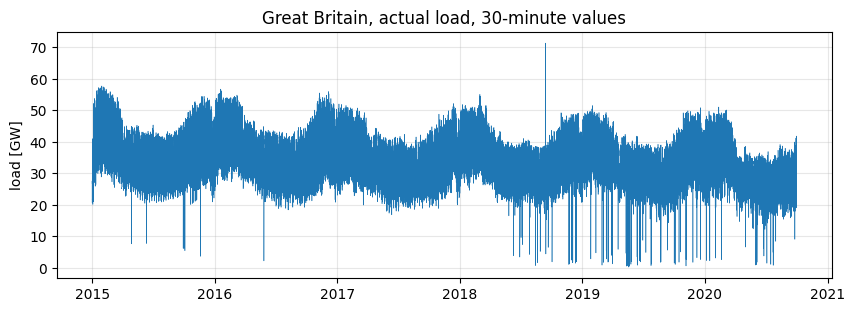

In [42]:
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(gb["timestamp"], gb["load_mw"] / 1000, linewidth=0.4, color="tab:blue")
ax.set_ylabel("load [GW]")
ax.set_title("Great Britain, actual load, 30-minute values")
ax.grid(alpha=0.3)
plt.show()

The seasonal pattern is clear, and so are the problems `describe()` hinted at: one spike to
71 GW and a number of values close to zero. They are in the source data. The suspicious rows:

In [43]:
suspicious = gb.filter((pl.col("load_mw") < 15_000) | (pl.col("load_mw") > 60_000))
print(suspicious.height, "suspicious half-hours")

suspicious.group_by(year=pl.col("timestamp").dt.year()).agg(
    n=pl.len(),
    lowest=pl.col("load_mw").min(),
    highest=pl.col("load_mw").max(),
).sort("year")

230 suspicious half-hours


year,n,lowest,highest
i32,u32,f64,f64
2015,11,3658.0,8139.0
2016,1,2203.0,2203.0
2018,32,713.0,71273.0
2019,96,248.0,14943.0
2020,90,804.0,14999.0


Polars also has a built-in `df.plot`, a thin layer over **Altair** (it must be installed; Colab
has it). Altair embeds the data in the chart and refuses more than 5,000 rows by default, so plot
an aggregated frame: here the daily mean.

In [44]:
daily_load = (
    gb.sort("timestamp")
    .group_by_dynamic("timestamp", every="1d")
    .agg(load_gw=pl.col("load_mw").mean() / 1000)
)
print(daily_load.height, "rows")

daily_load.plot.line(x="timestamp", y="load_gw").properties(width=700, height=220)

2101 rows


alt.Chart(...)

## 2.5 Combining data

| pandas | Polars | Note |
|--------|--------|------|
| `pd.concat([a, b])` | `pl.concat([a, b])` | `how="vertical"` (default), `"diagonal"`, `"horizontal"` |
| `pd.concat` over `glob` | `pl.read_csv("folder/*.csv")` | the reader accepts a glob pattern |
| `a.merge(b, on=..., how=...)` | `a.join(b, on=..., how=...)` | `how`: inner, left, right, full, semi, anti, cross |
| `validate="m:1"` | `validate="m:1"` | same idea |
| `pd.merge_asof(a, b, ...)` | `a.join_asof(b, ...)` | join on the nearest timestamp |

### Stacking files: `concat`

A very common real-world task: one file per month. We first write 2019 as twelve CSV files.

In [45]:
MONTHLY_DIR = DATA_DIR / "monthly"
MONTHLY_DIR.mkdir(exist_ok=True)

gb_2019 = gb.filter(pl.col("timestamp").dt.year() == 2019)
for (month,), part in gb_2019.group_by(pl.col("timestamp").dt.month(), maintain_order=True):
    part.write_csv(MONTHLY_DIR / f"gb_2019_{month:02d}.csv")

files = sorted(MONTHLY_DIR.glob("gb_2019_*.csv"))
print(len(files), "files:", files[0].name, "...", files[-1].name)

12 files: gb_2019_01.csv ... gb_2019_12.csv


In [46]:
# The pandas way, translated literally: read each file, then concatenate.
stacked = pl.concat([pl.read_csv(file, try_parse_dates=True) for file in files])

# The Polars way: let the reader expand the pattern (and keep track of the source file).
globbed = pl.read_csv(
    MONTHLY_DIR / "gb_2019_*.csv", try_parse_dates=True, include_file_paths="source_file"
)

print(stacked.shape, globbed.shape, "| identical to the original:", stacked.equals(gb_2019))
globbed.group_by("source_file").agg(rows=pl.len()).sort("source_file").head(3)

(17520, 5) (17520, 6) | identical to the original: True


source_file,rows
str,u32
"""data/monthly/gb_2019_01.csv""",1488
"""data/monthly/gb_2019_02.csv""",1344
"""data/monthly/gb_2019_03.csv""",1488


`concat` is strict: the frames must have the same columns and types. `how="diagonal"` takes the
union of the columns and fills the gaps with `null`, which is what `pd.concat` does by default.

In [47]:
january = pl.DataFrame({"timestamp": [date(2019, 1, 1)], "load_mw": [30_000.0]})
february = pl.DataFrame({"timestamp": [date(2019, 2, 1)], "load_mw": [31_000.0], "note": ["estimated"]})

try:
    pl.concat([january, february])
except pl.exceptions.ShapeError as err:
    print("ShapeError:", str(err).splitlines()[0])

pl.concat([january, february], how="diagonal")

ShapeError: unable to append to a DataFrame of width 2 with a DataFrame of width 3


timestamp,load_mw,note
date,f64,str
2019-01-01,30000.0,null
2019-02-01,31000.0,"""estimated"""


### Measurements plus metadata: `join`

The long `regional` table has a region code; the names live in the small `regions` table.
`validate="m:1"` states the relationship we expect (many readings, one region) and raises if the
data disagree.

In [48]:
regions

region,name,country
str,str,str
"""GB_GBN""","""Great Britain""","""United Kingdom"""
"""GB_NIR""","""Northern Ireland""","""United Kingdom"""
"""IE""","""Ireland""","""Ireland"""
"""CY""","""Cyprus""","""Cyprus"""


In [49]:
regional_named = regional.join(regions, on="region", how="left", validate="m:1")

(
    regional_named
    .group_by("country", "name")
    .agg(load_mean_mw=pl.col("load_mw").mean().round(0), load_max_mw=pl.col("load_mw").max())
    .sort("load_mean_mw", descending=True)
)

country,name,load_mean_mw,load_max_mw
str,str,f64,f64
"""United Kingdom""","""Great Britain""",34921.0,71273.0
"""Ireland""","""Ireland""",3191.0,5024.26
"""United Kingdom""","""Northern Ireland""",924.0,1715.0
"""Cyprus""","""Cyprus""",499.0,975.77


`semi` and `anti` joins filter one table by the keys of another, without adding columns.

In [50]:
island_of_ireland = pl.DataFrame({"region": ["IE", "GB_NIR"]})

print(regions.join(island_of_ireland, on="region", how="semi")["name"].to_list())
print(regions.join(island_of_ireland, on="region", how="anti")["name"].to_list())

['Northern Ireland', 'Ireland']
['Great Britain', 'Cyprus']


### Joining on the nearest timestamp: `join_asof`

Events are rarely logged exactly on the measurement grid. `join_asof` attaches to each row of
the left table the closest row of the right table in time: `strategy` is `"backward"` (last
reading at or before the event), `"forward"` or `"nearest"`, and `tolerance` limits how far to
look. Both tables must be sorted by the time key. It is the `merge_asof` of pandas.

In [51]:
events = pl.DataFrame(
    {
        "event_time": [
            datetime(2019, 1, 15, 18, 7, tzinfo=UTC),
            datetime(2019, 6, 2, 3, 44, tzinfo=UTC),
            datetime(2020, 3, 29, 1, 59, tzinfo=UTC),
        ],
        "event": ["evening peak alarm", "night maintenance", "clock change"],
    }
)

events.join_asof(
    gb.select("timestamp", "load_mw"),
    left_on="event_time",
    right_on="timestamp",
    strategy="backward",
    tolerance="30m",
)

event_time,event,timestamp,load_mw
"datetime[μs, UTC]",str,"datetime[μs, UTC]",f64
2019-01-15 18:07:00 UTC,"""evening peak alarm""",2019-01-15 18:00:00 UTC,48825.0
2019-06-02 03:44:00 UTC,"""night maintenance""",2019-06-02 03:30:00 UTC,18788.0
2020-03-29 01:59:00 UTC,"""clock change""",2020-03-29 01:30:00 UTC,23675.0


## 2.6 Grouping and reshaping

| pandas | Polars | Note |
|--------|--------|------|
| `groupby(keys).agg(...)` | `group_by(keys).agg(...)` | keys stay ordinary columns; group order is not defined |
| `groupby(keys)[col].transform("mean")` | `pl.col(col).mean().over(keys)` | keeps every row |
| `pivot(index, columns, values)` | `pivot(on, index=, values=)` | long to wide; eager only |
| `pivot_table(..., aggfunc=)` | `pivot(..., aggregate_function=)` | |
| `melt(id_vars, ...)` | `unpivot(index=, ...)` | wide to long |

### `group_by(...).agg(...)`: one row per group

In [52]:
(
    regional
    .group_by("region")
    .agg(
        n_valid=pl.col("load_mw").count(),
        load_mean=pl.col("load_mw").mean().round(1),
        load_p95=pl.col("load_mw").quantile(0.95).round(1),
        wind_share_mean=(pl.col("wind_onshore_mw") / pl.col("load_mw")).mean().round(3),
    )
    .sort("load_mean", descending=True)
)

region,n_valid,load_mean,load_p95,wind_share_mean
str,u32,f64,f64,f64
"""GB_GBN""",100786,34921.1,47628.0,0.08
"""IE""",99672,3191.2,4151.7,0.286
"""GB_NIR""",100362,924.1,1317.0,0.268
"""CY""",65836,499.4,737.4,0.055


In [53]:
# Group keys can be expressions: the average daily profile, working days versus weekends.
london = pl.col("timestamp").dt.convert_time_zone("Europe/London")

profile = (
    gb
    .group_by(hour=london.dt.hour(), is_weekend=london.dt.weekday() >= 6)
    .agg(load_mean_gw=(pl.col("load_mw").mean() / 1000).round(2))
    .sort("hour", "is_weekend")
)
profile.filter(pl.col("hour").is_in([4, 8, 18]))

hour,is_weekend,load_mean_gw
i8,bool,f64
4,false,24.81
4,true,23.45
8,false,39.63
8,true,32.21
18,false,42.87
18,true,39.24


### `.over()`: a group statistic on every row

`group_by().agg()` collapses each group to one row. `.over()` computes the same statistic but
**keeps every row**, like `groupby().transform()` in pandas or a window function in SQL.

In [54]:
(
    regional
    .select(
        "timestamp",
        "region",
        "load_mw",
        region_mean=pl.col("load_mw").mean().over("region").round(1),
        relative_load=(pl.col("load_mw") / pl.col("load_mw").mean().over("region")).round(3),
        rank_in_region=pl.col("load_mw").rank(descending=True).over("region"),
    )
    .filter(pl.col("timestamp") == datetime(2019, 1, 15, 18, 0, tzinfo=UTC))
)

timestamp,region,load_mw,region_mean,relative_load,rank_in_region
"datetime[μs, UTC]",str,f64,f64,f64,f64
2019-01-15 18:00:00 UTC,"""GB_GBN""",48825.0,34921.1,1.398,3200.0
2019-01-15 18:00:00 UTC,"""GB_NIR""",1446.0,924.1,1.565,1359.0
2019-01-15 18:00:00 UTC,"""IE""",4586.94,3191.2,1.437,685.0
2019-01-15 18:00:00 UTC,"""CY""",734.13,499.4,1.47,3459.5


### Long to wide and back: `pivot` and `unpivot`

`pivot` is eager only, because the output columns depend on the data.

In [55]:
monthly_long = (
    regional.sort("region", "timestamp")
    .group_by_dynamic("timestamp", every="1mo", group_by="region")
    .agg(load_mean=pl.col("load_mw").mean().round(1))
    .sort("region", "timestamp")
)
print(monthly_long.shape)

monthly_wide = monthly_long.pivot("region", index="timestamp", values="load_mean")
monthly_wide.tail(3)

(280, 3)


timestamp,CY,GB_GBN,GB_NIR,IE
"datetime[μs, UTC]",f64,f64,f64,f64
2020-07-01 00:00:00 UTC,562.2,26591.8,777.1,3085.3
2020-08-01 00:00:00 UTC,587.1,28859.9,797.9,3147.8
2020-09-01 00:00:00 UTC,598.9,29411.5,837.4,3243.1


In [56]:
monthly_wide.unpivot(index="timestamp", variable_name="region", value_name="load_mean").tail(3)

timestamp,region,load_mean
"datetime[μs, UTC]",str,f64
2020-07-01 00:00:00 UTC,"""IE""",3085.3
2020-08-01 00:00:00 UTC,"""IE""",3147.8
2020-09-01 00:00:00 UTC,"""IE""",3243.1


The original file is itself "wide": the region is encoded in the column names. `unpivot` plus
a string expression turns any group of those columns into a tidy table.

In [57]:
all_loads = (
    power
    .select("utc_timestamp", cs.ends_with("load_actual_entsoe_transparency"))
    .unpivot(index="utc_timestamp", variable_name="series", value_name="load_mw")
    .with_columns(region=pl.col("series").str.extract(r"^(CY|GB_GBN|GB_NIR|GB_UKM|IE_sem|IE)_", 1))
)
all_loads.group_by("region").agg(
    n_valid=pl.col("load_mw").count(),
    load_mean=pl.col("load_mw").mean().round(1),
).sort("region")

region,n_valid,load_mean
str,u32,f64
"""CY""",65836,499.4
"""GB_GBN""",100786,34921.1
"""GB_NIR""",100362,924.1
"""GB_UKM""",100448,35835.1
"""IE""",99672,3191.2
"""IE_sem""",99494,4114.9


# Part 3 - Intermediate: time series

pandas does its time-series work through the index (`resample`, `rolling`, `asfreq` need a
`DatetimeIndex`). Polars has no index: the same tools take the **name of the time column**, and
they expect that column to be **sorted**.

In [58]:
gb = gb.sort("timestamp")                          # already sorted; say it explicitly
gb_pd = gb.to_pandas().set_index("timestamp")      # the pandas view, for comparisons
print(gb["timestamp"].is_sorted(), type(gb_pd.index).__name__)

True DatetimeIndex


## 3.1 Resampling and frequency

| pandas | Polars | Note |
|--------|--------|------|
| `resample("1h").mean()` | `group_by_dynamic("timestamp", every="1h").agg(...)` | |
| `resample(...).agg([...])` | several expressions inside `agg` | |
| `label=`, `closed=` | `label=`, `closed=` | same defaults for sub-daily windows: left / left |
| `groupby(key).resample(...)` | `group_by_dynamic(..., group_by=key)` | |
| `asfreq(...)`, upsampling | `upsample("timestamp", every=...)` | eager only |
| `pd.date_range(...)` | `pl.datetime_range(...)`, `pl.date_range(...)` | |
| `resample(...).ohlc()` | `first`, `max`, `min`, `last` inside `agg` | no shortcut |

### Downsampling

In [59]:
hourly = gb.group_by_dynamic("timestamp", every="1h").agg(load_mw=pl.col("load_mw").mean())
print(gb.height, "->", hourly.height, "rows")
hourly.slice(1, 3)

100802 -> 50401 rows


timestamp,load_mw
"datetime[μs, UTC]",f64
2015-01-01 00:00:00 UTC,26758.0
2015-01-01 01:00:00 UTC,27165.5
2015-01-01 02:00:00 UTC,24471.5


In [60]:
# Several aggregations at once.
daily = gb.group_by_dynamic("timestamp", every="1d").agg(
    load_mean=pl.col("load_mw").mean().round(1),
    load_min=pl.col("load_mw").min(),
    load_max=pl.col("load_mw").max(),
    n_valid=pl.col("load_mw").count(),
)
daily.slice(1, 3)

timestamp,load_mean,load_min,load_max,n_valid
"datetime[μs, UTC]",f64,f64,f64,u32
2015-01-01 00:00:00 UTC,28337.4,20629.0,36176.0,47
2015-01-02 00:00:00 UTC,30856.0,21437.0,40964.0,48
2015-01-03 00:00:00 UTC,31009.8,20119.0,40802.0,48


In [61]:
# Per group: add group_by. The frame must be sorted by time within each group.
(
    regional.sort("region", "timestamp")
    .group_by_dynamic("timestamp", every="1y", group_by="region")
    .agg(load_mean=pl.col("load_mw").mean().round(1))
    .filter(pl.col("timestamp").dt.year() == 2019)
    .sort("region")
)

region,timestamp,load_mean
str,"datetime[μs, UTC]",f64
"""CY""",2019-01-01 00:00:00 UTC,498.9
"""GB_GBN""",2019-01-01 00:00:00 UTC,34018.6
"""GB_NIR""",2019-01-01 00:00:00 UTC,900.3
"""IE""",2019-01-01 00:00:00 UTC,3317.9


### `label` and `closed`

Which samples fall in a bucket (`closed`), and is the bucket named by its start or by its end
(`label`)? For metered energy this matters: a value stamped 01:00 may describe the half-hour
*ending* at 01:00. Six consecutive half-hourly samples, grouped by hour in the four ways:

In [62]:
six = gb.slice(3, 6).select("timestamp", "load_mw")
print(six["timestamp"].dt.strftime("%H:%M").to_list())

for closed, label in [("left", "left"), ("left", "right"), ("right", "left"), ("right", "right")]:
    buckets = six.group_by_dynamic("timestamp", every="1h", closed=closed, label=label).agg(
        samples=pl.col("timestamp").dt.strftime("%H:%M"),
    )
    print(f"\nclosed={closed!r}, label={label!r}")
    for bucket, samples in buckets.select(pl.col("timestamp").dt.strftime("%H:%M"), "samples").rows():
        print(f"  {bucket}  <-  {samples}")

['00:30', '01:00', '01:30', '02:00', '02:30', '03:00']

closed='left', label='left'
  00:00  <-  ['00:30']
  01:00  <-  ['01:00', '01:30']
  02:00  <-  ['02:00', '02:30']
  03:00  <-  ['03:00']

closed='left', label='right'
  01:00  <-  ['00:30']
  02:00  <-  ['01:00', '01:30']
  03:00  <-  ['02:00', '02:30']
  04:00  <-  ['03:00']

closed='right', label='left'
  00:00  <-  ['00:30', '01:00']
  01:00  <-  ['01:30', '02:00']
  02:00  <-  ['02:30', '03:00']

closed='right', label='right'
  01:00  <-  ['00:30', '01:00']
  02:00  <-  ['01:30', '02:00']
  03:00  <-  ['02:30', '03:00']


In [63]:
# The same thing in pandas gives the same buckets.
print(gb_pd["load_mw"].iloc[3:9].resample("1h", closed="right", label="right").count())

timestamp
2015-01-01 01:00:00+00:00    2
2015-01-01 02:00:00+00:00    2
2015-01-01 03:00:00+00:00    2
Freq: h, Name: load_mw, dtype: int64


### Regular grids: `upsample`, and making gaps explicit

A logger that simply skips rows when it has nothing to report produces an irregular table where
gaps are invisible. `upsample` puts the table on a regular grid: the missing rows appear, filled
with `null`. This is the `asfreq` of pandas.

In [64]:
march_29 = pl.col("timestamp").is_between(
    datetime(2015, 3, 29, 0, 0, tzinfo=UTC), datetime(2015, 3, 29, 4, 30, tzinfo=UTC)
)
with_holes = gb.filter(march_29).select("timestamp", "load_mw").drop_nulls()   # rows are simply absent
print(with_holes["timestamp"].dt.strftime("%H:%M").to_list())

on_grid = with_holes.upsample("timestamp", every="30m")
print(with_holes.height, "->", on_grid.height, "rows,", on_grid["load_mw"].null_count(), "explicit gaps")
on_grid

['00:00', '00:30', '04:00', '04:30']
4 -> 10 rows, 6 explicit gaps


timestamp,load_mw
"datetime[μs, UTC]",f64
2015-03-29 00:00:00 UTC,30902.0
2015-03-29 00:30:00 UTC,31722.0
2015-03-29 01:00:00 UTC,null
2015-03-29 01:30:00 UTC,null
2015-03-29 02:00:00 UTC,null
2015-03-29 02:30:00 UTC,null
2015-03-29 03:00:00 UTC,null
2015-03-29 03:30:00 UTC,null
2015-03-29 04:00:00 UTC,25364.0


That gap is real and has a classic cause: it is the night of the switch to summer time
(29 March 2015), and the source lost three hours of British load.

Upsampling to a finer grid works the same way; then choose how to fill.

In [65]:
(
    gb.slice(60, 3).select("timestamp", "load_mw")
    .upsample("timestamp", every="15m")
    .with_columns(
        held=pl.col("load_mw").forward_fill(),
        linear=pl.col("load_mw").interpolate(),
    )
)

timestamp,load_mw,held,linear
"datetime[μs, UTC]",f64,f64,f64
2015-01-02 05:00:00 UTC,21437.0,21437.0,21437.0
2015-01-02 05:15:00 UTC,null,21437.0,21842.5
2015-01-02 05:30:00 UTC,22248.0,22248.0,22248.0
2015-01-02 05:45:00 UTC,null,22248.0,22825.5
2015-01-02 06:00:00 UTC,23403.0,23403.0,23403.0


### Ranges and duration strings

Polars uses one small language for durations everywhere (`every`, `period`, `window_size`,
`interval`): a number followed by a unit, and units can be combined (`"1h30m"`).

| Meaning | Polars | pandas (current aliases) |
|---------|--------|--------------------------|
| second, minute, hour | `"1s"`, `"1m"`, `"1h"` | `"s"`, `"min"`, `"h"` |
| day, week | `"1d"`, `"1w"` | `"D"`, `"W"` |
| month, quarter, year | `"1mo"`, `"1q"`, `"1y"` | `"MS"` / `"ME"`, `"QS"` / `"QE"`, `"YS"` / `"YE"` |

Mind the trap: in Polars `"1m"` is one **minute** and `"1mo"` one month. Calendar windows in
Polars are labelled by their start, so there is no month-start / month-end pair of aliases.

In [66]:
half_hours = pl.datetime_range(
    datetime(2020, 1, 1), datetime(2020, 1, 1, 2), interval="30m", time_zone="UTC", eager=True
)
months = pl.date_range(date(2020, 1, 1), date(2020, 6, 1), interval="1mo", eager=True)

print(half_hours.to_list()[:3])
print(months.to_list())

# A complete grid is also the direct way to check for missing rows.
grid = pl.DataFrame(
    {"timestamp": pl.datetime_range(gb["timestamp"].min(), gb["timestamp"].max(), interval="30m", eager=True)}
)
print("rows missing from the 30-minute grid:", grid.join(gb, on="timestamp", how="anti").height)

[datetime.datetime(2020, 1, 1, 0, 0, tzinfo=zoneinfo.ZoneInfo(key='UTC')), datetime.datetime(2020, 1, 1, 0, 30, tzinfo=zoneinfo.ZoneInfo(key='UTC')), datetime.datetime(2020, 1, 1, 1, 0, tzinfo=zoneinfo.ZoneInfo(key='UTC'))]
[datetime.date(2020, 1, 1), datetime.date(2020, 2, 1), datetime.date(2020, 3, 1), datetime.date(2020, 4, 1), datetime.date(2020, 5, 1), datetime.date(2020, 6, 1)]
rows missing from the 30-minute grid: 0


### Open, high, low, close

Useful to summarise any fluctuating signal per interval. Polars has no `ohlc()` shortcut: it is
four expressions. One difference to know: `first()` and `last()` return the first and last
**rows**, nulls included, while pandas skips missing values. Add `drop_nulls()` to match.

In [67]:
ohlc = gb.group_by_dynamic("timestamp", every="1d").agg(
    open=pl.col("load_mw").drop_nulls().first(),
    high=pl.col("load_mw").max(),
    low=pl.col("load_mw").min(),
    close=pl.col("load_mw").drop_nulls().last(),
)
print(ohlc.slice(1, 2))
print(gb_pd["load_mw"].resample("1D").ohlc().iloc[1:3])

shape: (2, 5)
┌─────────────────────────┬─────────┬─────────┬─────────┬─────────┐
│ timestamp               ┆ open    ┆ high    ┆ low     ┆ close   │
│ ---                     ┆ ---     ┆ ---     ┆ ---     ┆ ---     │
│ datetime[μs, UTC]       ┆ f64     ┆ f64     ┆ f64     ┆ f64     │
╞═════════════════════════╪═════════╪═════════╪═════════╪═════════╡
│ 2015-01-01 00:00:00 UTC ┆ 26758.0 ┆ 36176.0 ┆ 20629.0 ┆ 26878.0 │
│ 2015-01-02 00:00:00 UTC ┆ 25521.0 ┆ 40964.0 ┆ 21437.0 ┆ 28154.0 │
└─────────────────────────┴─────────┴─────────┴─────────┴─────────┘
                              open     high      low    close
timestamp                                                    
2015-01-01 00:00:00+00:00  26758.0  36176.0  20629.0  26878.0
2015-01-02 00:00:00+00:00  25521.0  40964.0  21437.0  28154.0


## 3.2 Window functions

| pandas | Polars | Note |
|--------|--------|------|
| `rolling(48).mean()` | `rolling_mean(window_size=48)` | window counted in **rows** |
| `rolling("1D").mean()` | `rolling_mean_by("timestamp", window_size="1d")` | window measured in **time** |
| `center=True` | `center=True` | row-based windows only |
| `min_periods=` | `min_samples=` | |
| `rolling(...).agg([...])` | `df.rolling("timestamp", period=...).agg(...)` | several statistics at once |
| `ewm(span=...).mean()` | `ewm_mean(span=...)` | also `ewm_mean_by(..., half_life=)` in time |
| `expanding().max()` | `cum_max()` | also `cum_sum`, `cum_min`, `cum_count` |

`rolling_*` exists for `mean`, `sum`, `min`, `max`, `std`, `var`, `median`, `quantile`.

### Rolling windows: rows versus time

In [68]:
rolled = gb.select(
    "timestamp",
    "load_mw",
    rows_48=pl.col("load_mw").rolling_mean(window_size=48),
    time_1d=pl.col("load_mw").rolling_mean_by("timestamp", window_size="1d"),
    centered=pl.col("load_mw").rolling_mean(window_size=48, center=True),
    lenient=pl.col("load_mw").rolling_mean(window_size=48, min_samples=1),
)
print(rolled.slice(3, 2))      # start of the series: not enough samples yet
print(rolled.slice(60, 2))

shape: (2, 6)
┌─────────────────────────┬─────────┬─────────┬─────────┬──────────┬─────────┐
│ timestamp               ┆ load_mw ┆ rows_48 ┆ time_1d ┆ centered ┆ lenient │
│ ---                     ┆ ---     ┆ ---     ┆ ---     ┆ ---      ┆ ---     │
│ datetime[μs, UTC]       ┆ f64     ┆ f64     ┆ f64     ┆ f64      ┆ f64     │
╞═════════════════════════╪═════════╪═════════╪═════════╪══════════╪═════════╡
│ 2015-01-01 00:30:00 UTC ┆ 26758.0 ┆ null    ┆ 26758.0 ┆ null     ┆ 26758.0 │
│ 2015-01-01 01:00:00 UTC ┆ 27561.0 ┆ null    ┆ 27159.5 ┆ null     ┆ 27159.5 │
└─────────────────────────┴─────────┴─────────┴─────────┴──────────┴─────────┘
shape: (2, 6)
┌─────────────────────────┬─────────┬───────────┬───────────┬──────────────┬───────────┐
│ timestamp               ┆ load_mw ┆ rows_48   ┆ time_1d   ┆ centered     ┆ lenient   │
│ ---                     ┆ ---     ┆ ---       ┆ ---       ┆ ---          ┆ ---       │
│ datetime[μs, UTC]       ┆ f64     ┆ f64       ┆ f64       ┆ f64        

In [69]:
# Same numbers as pandas.
check = gb_pd["load_mw"]
print("rolling(48)             :", check.rolling(48).mean().iloc[60:62].round(3).tolist())
print("rolling('1D')           :", check.rolling("1D").mean().iloc[60:62].round(3).tolist())
print("rolling(48, center=True):", check.rolling(48, center=True).mean().iloc[60:62].round(3).tolist())

rolling(48)             : [28003.25, 28036.875]
rolling('1D')           : [28003.25, 28036.875]
rolling(48, center=True): [29671.854, 29754.854]


On a regular, complete grid the two coincide (48 half-hours are one day). They differ as soon as
samples are missing or irregular: the row window silently stretches over more time, the time
window does not. **With real sensor data prefer the time-based form.** Row-based windows also
return `null` until the window is full (`min_samples` relaxes that); time-based ones need a
single sample by default.

For several statistics over the same window there is a `rolling` context, the sibling of
`group_by_dynamic`:

In [70]:
(
    gb.rolling("timestamp", period="1d")
    .agg(
        load_mean=pl.col("load_mw").mean().round(1),
        load_std=pl.col("load_mw").std().round(1),
        load_max=pl.col("load_mw").max(),
        n=pl.col("load_mw").count(),
    )
    .slice(60, 3)
)

timestamp,load_mean,load_std,load_max,n
"datetime[μs, UTC]",f64,f64,f64,u32
2015-01-02 05:00:00 UTC,28003.2,5006.4,36176.0,48
2015-01-02 05:30:00 UTC,28036.9,4961.1,36176.0,48
2015-01-02 06:00:00 UTC,28094.7,4888.6,36176.0,48


### Exponential smoothing

`ewm_mean` behaves like a first-order low-pass filter: each output is a weighted mean of the
past, with weights decaying exponentially. `span`, `half_life`, `com` and `alpha` are four ways
to give the same decay, as in pandas. `ewm_mean_by` takes the half-life as a duration and uses the
real timestamps, for irregular sampling.

In [71]:
smoothed = gb.select(
    "timestamp",
    "load_mw",
    ewm_span_48=pl.col("load_mw").ewm_mean(span=48),
    ewm_6h=pl.col("load_mw").ewm_mean_by("timestamp", half_life="6h"),
)
print(smoothed.slice(60, 2))
print("pandas ewm(span=48):", gb_pd["load_mw"].ewm(span=48).mean().iloc[60:62].round(3).tolist())

shape: (2, 4)
┌─────────────────────────┬─────────┬──────────────┬──────────────┐
│ timestamp               ┆ load_mw ┆ ewm_span_48  ┆ ewm_6h       │
│ ---                     ┆ ---     ┆ ---          ┆ ---          │
│ datetime[μs, UTC]       ┆ f64     ┆ f64          ┆ f64          │
╞═════════════════════════╪═════════╪══════════════╪══════════════╡
│ 2015-01-02 05:00:00 UTC ┆ 21437.0 ┆ 27110.231606 ┆ 26690.894059 │
│ 2015-01-02 05:30:00 UTC ┆ 22248.0 ┆ 26893.207399 ┆ 26441.533576 │
└─────────────────────────┴─────────┴──────────────┴──────────────┘
pandas ewm(span=48): [27110.232, 26893.207]


### Cumulative ("expanding") statistics

Running totals and running extremes. The integral of power over time is energy: each half-hour
at `P` MW is `P / 2` MWh.

In [72]:
gb.select(
    "timestamp",
    "load_mw",
    running_peak=pl.col("load_mw").cum_max(),
    energy_gwh=(pl.col("load_mw") * 0.5).cum_sum() / 1000,
    running_mean=(pl.col("load_mw").cum_sum() / pl.col("load_mw").cum_count()).round(1),
).slice(60, 3)

timestamp,load_mw,running_peak,energy_gwh,running_mean
"datetime[μs, UTC]",f64,f64,f64,f64
2015-01-02 05:00:00 UTC,21437.0,36176.0,792.7955,27337.8
2015-01-02 05:30:00 UTC,22248.0,36176.0,803.9195,27251.5
2015-01-02 06:00:00 UTC,23403.0,36176.0,815.621,27187.4


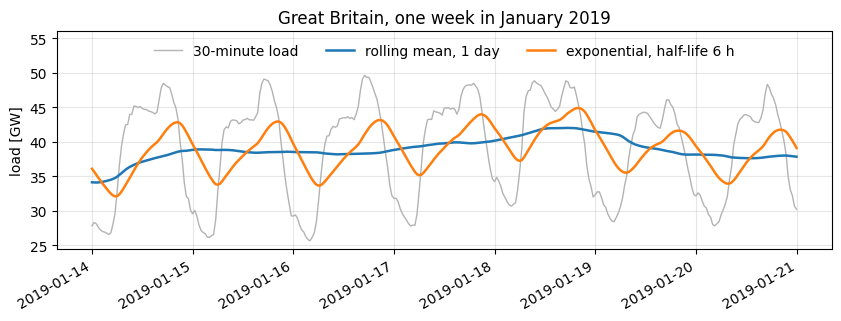

In [73]:
# Compute on the whole series, then cut the week to plot: windows need their history.
week = gb.with_columns(
    rolling_1d=pl.col("load_mw").rolling_mean_by("timestamp", window_size="1d"),
    ewm_6h=pl.col("load_mw").ewm_mean_by("timestamp", half_life="6h"),
).filter(
    pl.col("timestamp").is_between(datetime(2019, 1, 14, tzinfo=UTC), datetime(2019, 1, 21, tzinfo=UTC))
)

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(week["timestamp"], week["load_mw"] / 1000, color="0.7", linewidth=1.0, label="30-minute load")
ax.plot(week["timestamp"], week["rolling_1d"] / 1000, color="tab:blue", linewidth=1.8, label="rolling mean, 1 day")
ax.plot(week["timestamp"], week["ewm_6h"] / 1000, color="tab:orange", linewidth=1.8, label="exponential, half-life 6 h")
ax.set_ylabel("load [GW]")
ax.set_title("Great Britain, one week in January 2019")
ax.set_ylim(top=56)
ax.legend(frameon=False, ncol=3, loc="upper center")
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.show()

## 3.3 Changes and lags

| pandas | Polars | Note |
|--------|--------|------|
| `shift(n)` | `shift(n)` | lag features |
| `diff()` | `diff()` | |
| `pct_change()` | `pct_change()` | |
| `df["x"].diff() / df.index.to_series().diff().dt.total_seconds()` | `pl.col("x").diff() / pl.col("timestamp").diff().dt.total_seconds()` | true derivative; the time is just another column |

With several series in one long table, add `.over("region")` after sorting, otherwise the last
sample of one region leaks into the first sample of the next.

In [74]:
changes = gb.select(
    "timestamp",
    "load_mw",
    previous=pl.col("load_mw").shift(1),
    same_time_yesterday=pl.col("load_mw").shift(48),
    delta=pl.col("load_mw").diff(),
    pct=pl.col("load_mw").pct_change().round(4),
    ramp_mw_per_min=(pl.col("load_mw").diff() / pl.col("timestamp").diff().dt.total_minutes()).round(2),
)
changes.slice(60, 3)

timestamp,load_mw,previous,same_time_yesterday,delta,pct,ramp_mw_per_min
"datetime[μs, UTC]",f64,f64,f64,f64,f64,f64
2015-01-02 05:00:00 UTC,21437.0,21499.0,21733.0,-62.0,-0.0029,-2.07
2015-01-02 05:30:00 UTC,22248.0,21437.0,20634.0,811.0,0.0378,27.03
2015-01-02 06:00:00 UTC,23403.0,22248.0,20629.0,1155.0,0.0519,38.5


In [75]:
# The pandas idiom from the session, for comparison.
series = gb_pd["load_mw"]
ramp_pd = series.diff() / series.index.to_series().diff().dt.total_seconds() * 60
print(ramp_pd.iloc[60:63].round(2).tolist())

[-2.07, 27.03, 38.5]


### Detecting steps and spikes

Real demand does not change by tens of gigawatts in half an hour. Sorting by the size of the
step finds the bad values seen in the plot of section 2.4 at once: each isolated bad sample
shows up as a jump down and a jump back.

In [76]:
(
    changes
    .with_columns(abs_delta=pl.col("delta").abs())
    .top_k(6, by="abs_delta")
    .select("timestamp", "previous", "load_mw", "delta")
)

timestamp,previous,load_mw,delta
"datetime[μs, UTC]",f64,f64,f64
2015-11-19 16:30:00 UTC,3658.0,51839.0,48181.0
2019-11-26 17:00:00 UTC,1749.0,48516.0,46767.0
2019-02-28 18:30:00 UTC,863.0,46580.0,45717.0
2019-02-28 18:00:00 UTC,46300.0,863.0,-45437.0
2019-11-26 16:30:00 UTC,46677.0,1749.0,-44928.0
2019-03-18 16:30:00 UTC,1817.0,46077.0,44260.0


In [77]:
# A simple, physically motivated filter: mask samples reached by an implausible ramp,
# then fill short gaps in time. limit keeps long outages as gaps.
MAX_STEP_MW = 8_000

cleaned = gb.with_columns(
    load_clean=pl.when(pl.col("load_mw").diff().abs() > MAX_STEP_MW)
    .then(None)
    .otherwise(pl.col("load_mw"))
).with_columns(
    load_clean=pl.when(pl.col("load_clean") < 15_000).then(None).otherwise(pl.col("load_clean"))
).with_columns(load_filled=pl.col("load_clean").forward_fill(limit=4))

cleaned.select(
    raw_min=pl.col("load_mw").min(),
    raw_max=pl.col("load_mw").max(),
    clean_min=pl.col("load_clean").min(),
    clean_max=pl.col("load_clean").max(),
    masked=pl.col("load_clean").null_count() - pl.col("load_mw").null_count(),
    still_missing=pl.col("load_filled").null_count(),
)

raw_min,raw_max,clean_min,clean_max,masked,still_missing
f64,f64,f64,f64,u32,u32
248.0,71273.0,15038.0,57678.0,359,79


### Lag features per region

In a long table every lag must stay inside its own group.

In [78]:
(
    regional.sort("region", "timestamp")
    .select(
        "timestamp",
        "region",
        "load_mw",
        load_lag_1d=pl.col("load_mw").shift(48).over("region"),
        load_change_1d=pl.col("load_mw").diff(48).over("region"),
    )
    .filter(pl.col("timestamp") == datetime(2019, 1, 15, 18, 0, tzinfo=UTC))
)

timestamp,region,load_mw,load_lag_1d,load_change_1d
"datetime[μs, UTC]",str,f64,f64,f64
2019-01-15 18:00:00 UTC,"""CY""",734.13,746.71,-12.58
2019-01-15 18:00:00 UTC,"""GB_GBN""",48825.0,47986.0,839.0
2019-01-15 18:00:00 UTC,"""GB_NIR""",1446.0,1481.0,-35.0
2019-01-15 18:00:00 UTC,"""IE""",4586.94,4613.03,-26.09


# Part 4 - Beyond pandas

What has no counterpart in the pandas session: the lazy API and its optimiser, the streaming
engine of Polars 2.0, and what they mean in practice.

## 4.1 The lazy API

Everything so far was **eager**: each call ran immediately on data in memory. In **lazy** mode
you describe the whole query on a `LazyFrame`; nothing runs until `collect()`. In between, the
query optimiser rewrites the plan. Two optimisations give most of the benefit:

- **projection pushdown**: read only the columns the query uses;
- **predicate pushdown**: apply filters while reading.

`pl.scan_csv` / `pl.scan_parquet` start a lazy query from a file; `df.lazy()` from a DataFrame.

In [79]:
lazy_query = (
    pl.scan_csv(CSV_PATH, schema_overrides=schema_overrides, try_parse_dates=True)
    .filter(pl.col("utc_timestamp").dt.year() == 2019)
    .group_by(month=pl.col("utc_timestamp").dt.month())
    .agg(load_mean=pl.col("GB_GBN_load_actual_entsoe_transparency").mean())
    .sort("month")
)
print(type(lazy_query).__name__)     # nothing has been read yet

LazyFrame


In [80]:
# The optimised plan, read bottom-up: 2 of 41 columns are parsed (PROJECT) and the filter is
# applied inside the scan (SELECTION).
print(lazy_query.explain())

SORT BY [col("month")]
  AGGREGATE[maintain_order: false]
    [col("GB_GBN_load_actual_entsoe_transparency").mean().alias("load_mean")] BY [col("utc_timestamp").dt.month().alias("month")]
    FROM
    Csv SCAN [data/time_series_30min_singleindex.csv]
    PROJECT 2/41 COLUMNS
    SELECTION: (col("utc_timestamp").dt.year() == 2019)
    ESTIMATED ROWS: 454750


In [81]:
# The output schema is known without touching the data: use it to validate a pipeline up front.
print(lazy_query.collect_schema())

lazy_query.collect().head(3)

Schema({'month': Int8, 'load_mean': Float64})


month,load_mean
i8,f64
1,38575.486559
2,38369.155506
3,36572.926747


### Convert once to Parquet

CSV carries no types and must be parsed every time. Parquet stores the schema, is compressed and
columnar, and lets the reader skip what a query does not need.

In [82]:
PARQUET_PATH = DATA_DIR / "opsd_30min.parquet"
power.write_parquet(PARQUET_PATH)

print(f"CSV     {CSV_PATH.stat().st_size / 1e6:6.1f} MB")
print(f"Parquet {PARQUET_PATH.stat().st_size / 1e6:6.1f} MB")

timed("read_csv with declared schema", lambda: pl.read_csv(CSV_PATH, schema_overrides=schema_overrides, try_parse_dates=True))
timed("read_parquet", lambda: pl.read_parquet(PARQUET_PATH))
timed(
    "scan_parquet, 2 columns, one year",
    lambda: pl.scan_parquet(PARQUET_PATH)
    .filter(pl.col("utc_timestamp").dt.year() == 2019)
    .select("utc_timestamp", "IE_sem_price_day_ahead")
    .collect(),
)

CSV       39.1 MB
Parquet    8.7 MB
read_csv with declared schema              194 ms   (100802, 41)


read_parquet                                46 ms   (100802, 41)
scan_parquet, 2 columns, one year            8 ms   (17520, 2)


## 4.2 Polars 2.0: streaming engine by default, and row order

Since Polars 2.0, `collect()` on a `LazyFrame` runs on the **streaming engine**: data is
processed in batches, so a query can handle inputs larger than RAM, and some operations (sorts,
window functions) can spill to disk. Eager `DataFrame` methods still use the in-memory engine.

The practical consequence: the streaming engine **does not guarantee row order** for operations
that do not need it. The upgrade guide names `join`, `unpivot` and `group_by`. The join is the one
that changes behaviour for existing code: in Polars 1.x a left join returned the rows in the
order of the left table; a lazy left join in 2.0 may not.

In [83]:
REGIONAL_PATH = DATA_DIR / "regional.parquet"
regional.write_parquet(REGIONAL_PATH)
left_order = regional.select("timestamp", "region")


def keeps_left_order(result: pl.DataFrame) -> bool:
    """True if the rows come back in the same order as the left table."""
    return result.select("timestamp", "region").equals(left_order)


N_RUNS = 8
lazy_join = pl.scan_parquet(REGIONAL_PATH).join(regions.lazy(), on="region", how="left")
lazy_join_ordered = pl.scan_parquet(REGIONAL_PATH).join(
    regions.lazy(), on="region", how="left", maintain_order="left"
)

results = {
    "lazy join, default": sum(keeps_left_order(lazy_join.collect()) for _ in range(N_RUNS)),
    "lazy join, maintain_order='left'": sum(
        keeps_left_order(lazy_join_ordered.collect()) for _ in range(N_RUNS)
    ),
    "eager DataFrame.join": sum(
        keeps_left_order(regional.join(regions, on="region", how="left")) for _ in range(N_RUNS)
    ),
}
for label, hits in results.items():
    print(f"{label:<34} left order kept in {hits} of {N_RUNS} runs")

lazy join, default                 left order kept in 0 of 8 runs
lazy join, maintain_order='left'   left order kept in 8 of 8 runs
eager DataFrame.join               left order kept in 8 of 8 runs


The first number changes from run to run and is usually far below 8. For time series this
matters: `diff`, `shift` and rolling windows assume sorted rows. **If the order matters, say so**:
pass `maintain_order` to the join, or sort explicitly afterwards.

`group_by` is a different story: it never returned the groups in a defined order, eager or lazy,
in Polars 1.x as well.

In [84]:
group_orders = {
    tuple(regional.group_by("region").agg(pl.len())["region"]) for _ in range(N_RUNS)
}
print(f"eager group_by: {len(group_orders)} different group orders in {N_RUNS} runs")
print(regional.group_by("region", maintain_order=True).agg(n=pl.len())["region"].to_list())

eager group_by: 8 different group orders in 8 runs
['GB_GBN', 'GB_NIR', 'IE', 'CY']


## 4.3 How fast, really?

Three measurements, from small to large. Timings depend on the CPU, on the number of cores and on
the data, so **run the cells on your own machine**; the saved output comes from a small 2-core
machine, which is also what a free Colab runtime gives you.

### On this dataset: 400,000 rows

In [85]:
def best_of(func, repeats: int = 3) -> float:
    """Return the best wall-clock time in seconds over `repeats` runs."""
    timings = []
    for _ in range(repeats):
        tic = time.perf_counter()
        func()
        timings.append(time.perf_counter() - tic)
    return min(timings)


def compare(benchmarks: dict, repeats: int = 3) -> None:
    """Time (pandas, polars) pairs of functions and print one line per pair."""
    print(f"{'operation':<38}{'pandas':>10}{'polars':>10}{'ratio':>8}")
    for label, (run_pandas, run_polars) in benchmarks.items():
        t_pandas, t_polars = best_of(run_pandas, repeats), best_of(run_polars, repeats)
        print(f"{label:<38}{t_pandas * 1000:>8.0f}ms{t_polars * 1000:>8.0f}ms{t_pandas / t_polars:>7.1f}x")


regional_sorted = regional.sort("region", "timestamp")
regional_pd = regional_sorted.to_pandas()
regional_pd_indexed = regional_pd.set_index("timestamp")

print(f"rows: {regional.height:,} | threads available to Polars: {pl.thread_pool_size()}\n")
compare(
    {
        "read the 37 MB CSV": (
            lambda: pd.read_csv(CSV_PATH),
            lambda: pl.read_csv(CSV_PATH, schema_overrides=schema_overrides, try_parse_dates=True),
        ),
        "mean by region, hour and weekday": (
            lambda: regional_pd.groupby(
                ["region", regional_pd["timestamp"].dt.hour, regional_pd["timestamp"].dt.dayofweek]
            )["load_mw"].mean(),
            lambda: regional_sorted.group_by(
                "region", hour=pl.col("timestamp").dt.hour(), weekday=pl.col("timestamp").dt.weekday()
            ).agg(pl.col("load_mw").mean()),
        ),
        "forward fill and diff, per region": (
            lambda: regional_pd.groupby("region")["load_mw"].ffill().groupby(regional_pd["region"]).diff(),
            lambda: regional_sorted.select(pl.col("load_mw").forward_fill().diff().over("region")),
        ),
        "hourly resample, per region": (
            lambda: regional_pd_indexed.groupby("region")["load_mw"].resample("1h").mean(),
            lambda: regional_sorted.group_by_dynamic("timestamp", every="1h", group_by="region").agg(
                pl.col("load_mw").mean()
            ),
        ),
    }
)

rows: 403,208 | threads available to Polars: 2

operation                                 pandas    polars   ratio


read the 37 MB CSV                         390ms     157ms    2.5x


mean by region, hour and weekday            47ms      20ms    2.4x
forward fill and diff, per region           37ms       5ms    6.9x


hourly resample, per region                 59ms      72ms    0.8x


At this size the two libraries are in the same range: Polars is ahead on parsing the file and on
group operations, and pandas' `resample` holds its own. Nobody waits for either.

### At scale: 5 million rows

To see a difference we need more data. A synthetic measurement table: 1,000 sensors, one value per
minute, in arrival (shuffled) order, plus a small table of sensor metadata. Raise `N_STEPS` if your
machine has memory to spare.

In [86]:
N_SENSORS = 1_000
N_STEPS = 5_000          # minutes: 1,000 x 5,000 = 5 million rows


def make_sensor_data(n_sensors: int, n_steps: int, seed: int = 0) -> tuple[pl.DataFrame, pl.DataFrame]:
    """Synthetic long table (one row per sensor and minute, shuffled) and its metadata table."""
    rng = np.random.default_rng(seed)
    sensors = pl.DataFrame(
        {
            "sensor_id": [f"S{i:05d}" for i in range(n_sensors)],
            "site": [f"site_{i % 50:02d}" for i in range(n_sensors)],
            "kind": [("temperature", "pressure", "flow", "vibration")[i % 4] for i in range(n_sensors)],
        }
    )
    n_rows = n_sensors * n_steps
    times = pl.datetime_range(
        datetime(2026, 1, 1), datetime(2026, 1, 1) + timedelta(minutes=n_steps - 1), interval="1m", eager=True
    )
    measurements = (
        pl.DataFrame({"timestamp": times})
        .join(sensors.select("sensor_id"), how="cross")
        .with_columns(
            value=pl.Series(rng.normal(50, 10, n_rows)),
            quality=pl.Series(rng.integers(0, 100, n_rows, dtype=np.int32)),
        )
        .sample(fraction=1.0, shuffle=True, seed=seed)
    )
    return measurements, sensors


measurements, sensors = make_sensor_data(N_SENSORS, N_STEPS)
measurements_pd = measurements.to_pandas()
sensors_pd = sensors.to_pandas()

MEASUREMENTS_PATH = DATA_DIR / "measurements.parquet"
measurements.write_parquet(MEASUREMENTS_PATH)

print(f"rows: {measurements.height:,}")
print(f"in memory, Polars : {measurements.estimated_size('mb'):6.0f} MB")
print(f"in memory, pandas : {measurements_pd.memory_usage(deep=True).sum() / 1e6:6.0f} MB")
print(f"on disk, Parquet  : {MEASUREMENTS_PATH.stat().st_size / 1e6:6.0f} MB")
measurements.head(3)

rows: 5,000,000
in memory, Polars :    124 MB
in memory, pandas :    375 MB
on disk, Parquet  :     57 MB


timestamp,sensor_id,value,quality
datetime[μs],str,f64,i32
2026-01-03 04:09:00,"""S00899""",47.605883,49
2026-01-03 09:37:00,"""S00328""",53.51867,66
2026-01-02 15:19:00,"""S00581""",18.24722,91


The memory gap is the text column: Polars stores strings in Arrow buffers; pandas 2 stores one
Python object per value (pandas 3 has an Arrow-backed string type and is much closer).

Single operations first, each written the idiomatic way in both libraries.

In [87]:
compare(
    {
        "filter two conditions, then arithmetic": (
            lambda: measurements_pd[
                (measurements_pd["quality"] > 10) & (measurements_pd["value"] > 55)
            ].assign(scaled=lambda d: d["value"] * 1.8 + 32),
            lambda: measurements.filter((pl.col("quality") > 10) & (pl.col("value") > 55)).with_columns(
                scaled=pl.col("value") * 1.8 + 32
            ),
        ),
        "text operation on 5 million strings": (
            lambda: measurements_pd["sensor_id"].str.slice(1).astype("int32"),
            lambda: measurements.select(pl.col("sensor_id").str.slice(1).cast(pl.Int32)),
        ),
        "join with the metadata table": (
            lambda: measurements_pd.merge(sensors_pd, on="sensor_id", how="left"),
            lambda: measurements.join(sensors, on="sensor_id", how="left"),
        ),
        "join, then mean by site and kind": (
            lambda: measurements_pd.merge(sensors_pd, on="sensor_id", how="left")
            .groupby(["site", "kind"])["value"]
            .mean(),
            lambda: measurements.join(sensors, on="sensor_id", how="left")
            .group_by("site", "kind")
            .agg(pl.col("value").mean()),
        ),
        "mean, std, max by sensor": (
            lambda: measurements_pd.groupby("sensor_id")["value"].agg(["mean", "std", "max"]),
            lambda: measurements.group_by("sensor_id").agg(
                mean=pl.col("value").mean(), std=pl.col("value").std(), max=pl.col("value").max()
            ),
        ),
        "sort by sensor and time": (
            lambda: measurements_pd.sort_values(["sensor_id", "timestamp"]),
            lambda: measurements.sort("sensor_id", "timestamp"),
        ),
    },
    repeats=2,
)

operation                                 pandas    polars   ratio


filter two conditions, then arithmetic     103ms      20ms    5.0x


text operation on 5 million strings       1067ms     110ms    9.7x


join with the metadata table               787ms      84ms    9.4x


join, then mean by site and kind          1413ms     114ms   12.4x


mean, std, max by sensor                   302ms     210ms    1.4x


sort by sensor and time                   1100ms    1894ms    0.6x


The picture is uneven, and worth reading as it is:

- **joins, text operations and filters** are several times faster in Polars, even on two cores;
- a **plain group-by** is roughly on par at this size and core count;
- the **two-key sort** is faster in pandas here.

So "Polars is always N times faster" is not a claim to repeat. What these single operations do
not show is the part that matters most in practice: a real analysis is a *chain* of them.

### A whole pipeline: the optimiser at work

The question: hourly mean per site, for temperature sensors only, keeping readings with
`quality >= 50`, starting from the Parquet file. Four ways to write it.

In [88]:
def pandas_step_by_step() -> pd.DataFrame:
    """The natural way to write it: read, join, filter, group."""
    table = pd.read_parquet(MEASUREMENTS_PATH)
    return (
        table.merge(sensors_pd, on="sensor_id")
        .query("kind == 'temperature' and quality >= 50")
        .assign(hour=lambda d: d["timestamp"].dt.floor("h"))
        .groupby(["site", "hour"], as_index=False)["value"]
        .mean()
    )


def pandas_optimised_by_hand() -> pd.DataFrame:
    """The same result after reordering the steps by hand: filter early, join less."""
    table = pd.read_parquet(MEASUREMENTS_PATH, filters=[("quality", ">=", 50)])
    wanted = sensors_pd.loc[sensors_pd["kind"] == "temperature", ["sensor_id", "site"]]
    return (
        table.merge(wanted, on="sensor_id")
        .assign(hour=lambda d: d["timestamp"].dt.floor("h"))
        .groupby(["site", "hour"], as_index=False)["value"]
        .mean()
    )


def polars_eager() -> pl.DataFrame:
    """Polars, same order of steps as the first pandas version."""
    return (
        pl.read_parquet(MEASUREMENTS_PATH)
        .join(sensors, on="sensor_id")
        .filter((pl.col("kind") == "temperature") & (pl.col("quality") >= 50))
        .group_by("site", hour=pl.col("timestamp").dt.truncate("1h"))
        .agg(pl.col("value").mean())
    )


def polars_lazy_query() -> pl.LazyFrame:
    """The same steps in the same order, but lazy: only scan_parquet differs."""
    return (
        pl.scan_parquet(MEASUREMENTS_PATH)
        .join(sensors.lazy(), on="sensor_id")
        .filter((pl.col("kind") == "temperature") & (pl.col("quality") >= 50))
        .group_by("site", hour=pl.col("timestamp").dt.truncate("1h"))
        .agg(pl.col("value").mean())
    )


pipelines = {
    "pandas, step by step": pandas_step_by_step,
    "pandas, optimised by hand": pandas_optimised_by_hand,
    "polars, eager": polars_eager,
    "polars, lazy": lambda: polars_lazy_query().collect(),
}

reference = pandas_step_by_step().sort_values(["site", "hour"])["value"].to_numpy()
baseline = None
for label, run in pipelines.items():
    seconds = best_of(run)
    baseline = baseline or seconds
    result = run()
    values = (
        result.sort_values(["site", "hour"])["value"].to_numpy()
        if isinstance(result, pd.DataFrame)
        else result.sort("site", "hour")["value"].to_numpy()
    )
    same = np.allclose(values, reference)
    print(f"{label:<28}{seconds * 1000:>8.0f} ms   {baseline / seconds:>5.1f}x   same result: {same}")

pandas, step by step            1254 ms     1.0x   same result: True


pandas, optimised by hand        515 ms     2.4x   same result: True


polars, eager                    377 ms     3.3x   same result: True


polars, lazy                      95 ms    13.2x   same result: True


In [89]:
# Why the lazy version wins: read the plan bottom-up. The quality filter moved into the Parquet
# scan and the "temperature" filter moved onto the small table, so the join sees far fewer rows.
print(polars_lazy_query().explain())

AGGREGATE[maintain_order: false]
  [col("value").mean()] BY [col("site"), col("timestamp").dt.truncate(["1h"]).alias("hour")]
  FROM
  simple π 3/3 ["site", "timestamp", "value"]
    INNER JOIN:
    BUILD SIDE: PreferRight
    LEFT PLAN ON: [col("sensor_id")]
      simple π 3/3 ["timestamp", "value", ... 1 other column]
        Parquet SCAN [data/measurements.parquet]
        PROJECT 4/4 COLUMNS
        SELECTION: col("quality") >= 50
        ESTIMATED ROWS: 5000000
    RIGHT PLAN ON: [col("sensor_id")]
      simple π 2/2 ["site", "sensor_id"]
        FILTER col("kind") == "temperature"
        FROM
          simple π 3/3 ["site", "sensor_id", "kind"]
            DF ["sensor_id", "site", "kind"]; PROJECT */3 COLUMNS
    END INNER JOIN


The lazy query is the same code as the eager one, in the same order; the optimiser did what
`pandas_optimised_by_hand` does manually, and then ran it on all cores. That is the honest
summary of the speed difference:

- on **single operations** the gain ranges from nothing to about ten times, depending on the
  operation;
- on **pipelines read from files**, the lazy engine removes work you would otherwise have to
  remove by hand, and the gain is larger and comes for free;
- both grow with **more cores** (pandas uses one) and **more data**.

In [90]:
del measurements_pd, regional_pd, regional_pd_indexed    # free memory before the next sections

## 4.4 Pitfalls of the first week

1. **Looking for the index.** There is none. Keys are ordinary columns; alignment is done with
   explicit joins, time-series tools take the name of the time column.
2. **Assigning in place.** `df["new"] = ...` raises. Use `with_columns` and rebind the name.
3. **Using a column created in the same context.** Expressions in one context run in parallel:
   use a second `with_columns`.
4. **Relying on row order after `group_by` / `join`.** Sort, or pass `maintain_order`
   (`group_by` never had a defined order; lazy joins lost theirs in Polars 2.0).
5. **Treating `NaN` as missing.** Convert to `null` on the way in.
6. **Guessed schemas and guessed date formats.** Declare both.
7. **Bare strings in `then()`.** They are column names. Use `pl.lit("text")`.
8. **Forgetting parentheses** around comparisons combined with `&` / `|`.
9. **Python functions row by row** (`map_elements`). It works, but it leaves the fast path.
   Polars itself warns about it and, for simple lambdas, prints the native rewrite:

In [91]:
sample = gb.select("load_mw").drop_nulls()


def with_python_lambda() -> pl.DataFrame:
    return sample.select(pl.col("load_mw").map_elements(lambda mw: mw / 1000, return_dtype=pl.Float64))


def with_native_expression() -> pl.DataFrame:
    return sample.select(pl.col("load_mw") / 1000)


t_lambda = best_of(with_python_lambda)
t_native = best_of(with_native_expression)
print(f"map_elements      {t_lambda * 1000:8.2f} ms")
print(f"native expression {t_native * 1000:8.2f} ms   ({t_lambda / t_native:.0f}x faster)")

map_elements         13.11 ms
native expression     0.12 ms   (107x faster)


/tmp/ipykernel_1425/1924476193.py:5: PolarsInefficientMapWarning: 
Expr.map_elements is significantly slower than the native expressions API.
Only use if you absolutely CANNOT implement your logic otherwise.
Replace this expression...
  - pl.col("load_mw").map_elements(lambda mw: ...)
with this one instead:
  + pl.col("load_mw") / 1000

  return sample.select(pl.col("load_mw").map_elements(lambda mw: mw / 1000, return_dtype=pl.Float64))


In [92]:
# In-place assignment is not supported: the error message points to the right method.
try:
    gb["load_gw"] = gb["load_mw"] / 1000
except TypeError as err:
    print("TypeError:", " ".join(str(err).split()))

TypeError: DataFrame object does not support `Series` assignment by index Use `DataFrame.with_columns`.


If a computation truly has no expression equivalent, `map_batches` passes a whole `Series` to
your function (for example a NumPy or SciPy routine), which keeps the work vectorised.

## 4.5 Interop: NumPy, pandas, SQL

Conversion to NumPy and pandas is one method call, which is all scikit-learn, PyTorch and
matplotlib need. `to_pandas()` and `from_pandas()` go through Arrow and need `pyarrow`.

In [93]:
features = gb.drop_nulls().select(cs.float())

X = features.to_numpy()                       # 2-D array for scikit-learn / PyTorch
print(type(X).__name__, X.shape, X.dtype)

as_pandas = gb.head(3).to_pandas()
back_to_polars = pl.from_pandas(as_pandas)
print(type(as_pandas).__name__, "->", type(back_to_polars).__name__)

ndarray (100438, 4) float64
DataFrame -> DataFrame


In [94]:
# SQL runs on the same engine as the expression API.
pl.sql(
    """
    SELECT region,
           ROUND(AVG(load_mw), 1) AS load_mean,
           COUNT(load_mw)         AS n_valid
    FROM regional
    GROUP BY region
    ORDER BY load_mean DESC
    """
).collect()

region,load_mean,n_valid
str,f64,i64
"""GB_GBN""",34921.1,100786
"""IE""",3191.2,99672
"""GB_NIR""",924.1,100362
"""CY""",499.4,65836


## 4.6 The same query in pandas, Polars and PySpark

Mean load per region in 2019, highest first. PySpark is outside the scope of the session; it is
here for orientation, because its syntax is the closest relative of Polars: column expressions,
lazy by construction, no index.

In [95]:
regional_pandas = regional.to_pandas()

by_region_pandas = (
    regional_pandas[regional_pandas["timestamp"].dt.year == 2019]
    .groupby("region", as_index=False)
    .agg(load_mean=("load_mw", "mean"))
    .sort_values("load_mean", ascending=False)
)

by_region_polars = (
    regional.filter(pl.col("timestamp").dt.year() == 2019)
    .group_by("region")
    .agg(load_mean=pl.col("load_mw").mean())
    .sort("load_mean", descending=True)
)

print(by_region_pandas.round(1).to_string(index=False))
by_region_polars

region  load_mean
GB_GBN    34018.6
    IE     3317.9
GB_NIR      900.3
    CY      498.9


region,load_mean
str,f64
"""GB_GBN""",34018.640696
"""IE""",3317.890055
"""GB_NIR""",900.293807
"""CY""",498.878239


The PySpark version is not executed here (it needs a JVM and a Spark session). It was run
separately on Spark 4.2 against `data/regional.parquet` and returns the same four numbers.

```python
from pyspark.sql import functions as F

by_region_spark = (
    spark.read.parquet("data/regional.parquet")
    .filter(F.year("timestamp") == 2019)
    .groupBy("region")
    .agg(F.avg("load_mw").alias("load_mean"))
    .orderBy(F.desc("load_mean"))
)
```

`F.year` uses the Spark session time zone: set `spark.sql.session.timeZone` to `UTC` to match.

# 5. Cheat sheet: pandas to Polars

| Topic | pandas | Polars |
|-------|--------|--------|
| Inspect | `head`, `tail`, `shape`, `describe` | same names |
| | `dtypes`, `info()` | `schema`, `glimpse()`, `null_count()` |
| Dates | `pd.to_datetime(s, format=...)` | `pl.col("s").str.to_datetime(format)` |
| | `dayfirst=True` | explicit `format` |
| | `errors="coerce"` | `strict=False` |
| | `.dt.hour`, `.dt.dayofweek` (Mon = 0) | `.dt.hour()`, `.dt.weekday()` (Mon = 1) |
| | `.dt.tz_convert(tz)` | `.dt.convert_time_zone(tz)` |
| Cleaning | `isna`, `dropna`, `fillna` | `is_null`, `drop_nulls`, `fill_null` |
| | `ffill`, `bfill` | `forward_fill`, `backward_fill` |
| | `interpolate(method="time")` | `interpolate_by("timestamp")` |
| | `duplicated`, `drop_duplicates` | `is_duplicated`, `unique` |
| | `sort_index()` | `sort("timestamp")` |
| | `astype`, `pd.to_numeric(errors="coerce")` | `cast`, `cast(..., strict=False)` |
| Columns | `df["c"] = a * b`, `assign` | `with_columns(c=pl.col("a") * pl.col("b"))` |
| | index alignment | none: `join` explicitly |
| | `rename(columns=...)`, `drop(columns=...)` | `rename(...)`, `drop(...)` |
| Statistics | `sum`, `mean`, `min`, `max`, `std`, `quantile` | same names, as expressions |
| Plot | `df.plot()` | `df.plot.line(...)` (Altair), or matplotlib |
| Combine | `pd.concat`, `merge`, `merge_asof` | `pl.concat`, `join`, `join_asof` |
| Group | `groupby().agg()`, `transform` | `group_by().agg()`, `.over()` |
| Reshape | `pivot`, `pivot_table`, `melt` | `pivot`, `unpivot` |
| Resample | `resample("1h").mean()` | `group_by_dynamic("timestamp", every="1h").agg(...)` |
| | `asfreq` | `upsample` |
| | `pd.date_range` | `pl.datetime_range`, `pl.date_range` |
| | `.ohlc()` | `first`, `max`, `min`, `last` in `agg` |
| Windows | `rolling(n)`, `rolling("10min")` | `rolling_mean(n)`, `rolling_mean_by("timestamp", "10m")` |
| | `min_periods`, `center` | `min_samples`, `center` |
| | `ewm(span=...).mean()` | `ewm_mean(span=...)` |
| | `expanding().max()` | `cum_max()` |
| Lags | `shift`, `diff`, `pct_change` | same names |
| No pandas counterpart | | `scan_*` / `collect` (lazy), `explain()`, `sink_parquet` |

# 6. Exercises

Try them before looking at the solutions below.

1. **Grouping.** For each region, find the hour of the day (UTC) with the highest average load,
   and that average.
2. **Resampling and windows.** For Great Britain, compute the daily energy in GWh (each
   half-hour at `P` MW is `P / 2` MWh) and its 7-day rolling mean. Which are the three days with
   the highest daily energy?
3. **Lazy.** Starting from `pl.scan_parquet(PARQUET_PATH)`, compute the monthly mean of the
   day-ahead price `IE_sem_price_day_ahead` for 2017. Print the optimised plan and check how many
   columns are read.

### Solutions

In [96]:
# Exercise 1
(
    regional
    .group_by("region", hour=pl.col("timestamp").dt.hour())
    .agg(load_mean=pl.col("load_mw").mean().round(1))
    .sort("load_mean", descending=True)
    .group_by("region", maintain_order=True)
    .first()
)

region,hour,load_mean
str,i8,f64
"""GB_GBN""",17,41863.2
"""IE""",17,3778.1
"""GB_NIR""",18,1146.3
"""CY""",17,609.1


In [97]:
# Exercise 2
daily_energy = (
    gb.sort("timestamp")
    .group_by_dynamic("timestamp", every="1d")
    .agg(energy_gwh=(pl.col("load_mw") * 0.5).sum() / 1000, n_valid=pl.col("load_mw").count())
    .with_columns(energy_7d=pl.col("energy_gwh").rolling_mean_by("timestamp", window_size="7d"))
)
daily_energy.top_k(3, by="energy_gwh").with_columns(cs.float().round(1))

timestamp,energy_gwh,n_valid,energy_7d
"datetime[μs, UTC]",f64,u32,f64
2015-02-05 00:00:00 UTC,1121.5,48,1079.2
2015-02-02 00:00:00 UTC,1118.1,48,1069.2
2015-01-20 00:00:00 UTC,1116.6,48,1060.2


In [98]:
# Exercise 3
price_2017 = (
    pl.scan_parquet(PARQUET_PATH)
    .filter(pl.col("utc_timestamp").dt.year() == 2017)
    .group_by(month=pl.col("utc_timestamp").dt.month())
    .agg(price_mean=pl.col("IE_sem_price_day_ahead").mean().round(2))
    .sort("month")
)
print(price_2017.explain())
price_2017.collect().head(4)

SORT BY [col("month")]
  AGGREGATE[maintain_order: false]
    [col("IE_sem_price_day_ahead").mean().round().alias("price_mean")] BY [col("utc_timestamp").dt.month().alias("month")]
    FROM
    Parquet SCAN [data/opsd_30min.parquet]
    PROJECT 2/41 COLUMNS
    SELECTION: (col("utc_timestamp").dt.year() == 2017)
    ESTIMATED ROWS: 100802


month,price_mean
i8,f64
1,53.95
2,51.51
3,44.25
4,43.85


## Where to go next

- User guide: https://docs.pola.rs/user-guide/
- Coming from pandas: https://docs.pola.rs/user-guide/migration/pandas/
- Python API reference: https://docs.pola.rs/api/python/stable/reference/
- Polars 2.0 upgrade guide: https://docs.pola.rs/releases/upgrade/2/
- The dataset: https://data.open-power-system-data.org/time_series/2020-10-06